# AI Technologies (Basic Course) · Notebook 01
## Topic 1. Fundamentals of computer vision in Google Colab for UAV and UGV tasks

| Lesson | Type, duration | Title |
|---|---|---|
| **1.1** | Lecture, 2 h | Main tasks of computer vision in UAV and UGV systems |
| **1.2** | Group class, 2 h | Google Colab tools for processing electro-optical imagery |

Course: *AI Technologies (Basic Course)*, AIT-BC · Content module 1 · Kruty Heroes Military Institute of Telecommunications and Information Technology, Kyiv, 2026.

**How to work with this notebook**

1. Run the cells from top to bottom: *Runtime → Run all*, or `Shift+Enter` cell by cell. Section 0 is always run first; after a restart of the runtime it is run again.
2. Each code cell is preceded by a text cell that describes the block: purpose, parameters, what to observe.
3. Parameters are set in the form of a code cell (sliders, drop-down lists, check boxes). Cells marked **[auto]** in the title run again automatically after every change of a parameter.
4. The code of a form cell is hidden; a double click on the form (or *View → Show/hide code*) opens it.
5. A GPU is optional for this notebook; it is used only in block 1.2.2-A (*Runtime → Change runtime type → T4 GPU*).

**Data.** All demonstrations work on real images and videos of open data sets recorded by UAVs and a ground vehicle (block 0.2): thermal images and videos of a reconnaissance UAV (HIT-UAV), pixel-aligned visible and thermal image pairs of a UAV (Kust4K), visible images of camera drones over cities (VisDrone) and images of a ground vehicle in fields and forests (GOOSE). Every image has manual annotations: object boxes or pixel labels. Only the files used by the notebook are downloaded (about 80 MB). Degradations of the video signal in Lesson 1.1 are modelled on these real frames; the modelled part is stated in each block. Block 0.4 loads a frame of the participant's own for selected blocks.

**Contents**

- **0. Preparation** — 0.1 environment check · 0.2 course library and data sets · 0.3 entry check · 0.4 own frame (optional)
- **Lesson 1.1 (lecture)**
  - 1.1.1 AI, computer vision and their place in the electro-optical systems of UAVs and UGVs
  - 1.1.2 Typical applied computer vision tasks of FPV drones, reconnaissance UAVs and UGVs
  - 1.1.3 Classification, detection, segmentation and tracking of objects
  - 1.1.4 Problems of processing video data in combat conditions
- **Lesson 1.2 (group class)**
  - 1.2.1 Purpose and capabilities of Google Colab for prototyping computer vision algorithms
  - 1.2.2 GPU resources and integration with Google Drive
  - 1.2.3 Basic libraries: NumPy, OpenCV, Matplotlib, PyTorch, Ultralytics
  - 1.2.4 Typical project structure for UAV and UGV tasks
- **Summary**: control questions, glossary, data sources and licences

---
# 0. Preparation

### Block 0.1. Environment check

**Purpose.** Every computer vision experiment starts with a record of the software and hardware environment: the Python version, the versions of the libraries and the available accelerator. The record makes the results reproducible and helps to find the cause of an error (for example, a function that behaves differently in another version of OpenCV).

**What the code does.** Imports the basic libraries, detects whether the notebook runs in Google Colab, checks the GPU and prints a summary table.

**Parameters.** None.

In [1]:
#@title 0.1 Environment check { display-mode: "form" }
import sys, os, platform, time, json, math, importlib, shutil, subprocess
import numpy as np
import pandas as pd
import cv2
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display

try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

try:
    import torch
    TORCH_VERSION = torch.__version__
    CUDA_OK = torch.cuda.is_available()
    GPU_NAME = torch.cuda.get_device_name(0) if CUDA_OK else None
except ImportError:
    torch, TORCH_VERSION, CUDA_OK, GPU_NAME = None, "not installed", False, None

WORK_DIR = "/content" if IN_COLAB else os.getcwd()
env_table = pd.DataFrame([
    ("Environment", "Google Colab" if IN_COLAB else "local Jupyter"),
    ("Python", platform.python_version()),
    ("Operating system", platform.platform(terse=True)),
    ("CPU cores", os.cpu_count()),
    ("NumPy", np.__version__),
    ("OpenCV", cv2.__version__),
    ("Matplotlib", matplotlib.__version__),
    ("pandas", pd.__version__),
    ("PyTorch", TORCH_VERSION),
    ("GPU", GPU_NAME or "not available (CPU runtime)"),
    ("Working directory", WORK_DIR),
], columns=["Item", "Value"]).set_index("Item")
display(env_table)

,Value
Item,
Environment,local Jupyter
Python,3.12.15
Operating system,Windows-11
CPU cores,16
NumPy,2.5.4
OpenCV,5.0.0
Matplotlib,3.11.2
pandas,3.1.0
PyTorch,2.14.1+cpu


### Block 0.2. Course library and real data sets

**Purpose.** To install the course library `aitbc` and to connect four open data sets with manual annotations.

| Data set | Platform and sensor | Content used in the course | Annotation |
|---|---|---|---|
| **HIT-UAV** | UAV DJI Matrice M210 V2, thermal camera DJI Zenmuse XT2 (640 × 512 px, 25 mm lens, field of view 25° × 20°) | 2898 thermal images at flight altitudes of 60–130 m and camera angles of 30–90°, day and night; 5 thermal videos | boxes: Person, Car, Bicycle, OtherVehicle, DontCare |
| **Kust4K** | UAV hexacopter HET-3021C with visible and thermal cameras | 4024 pixel-aligned pairs of visible and thermal images 640 × 512 px over urban roads, day and night | pixel labels of 8 classes |
| **VisDrone2019-DET** (validation part) | camera drones over 14 cities | 548 visible images | boxes of pedestrians, cars, vans, trucks, buses, motorcycles and others |
| **GOOSE** (validation part) | ground vehicle with a front camera (2048 × 1000 px) | 962 images of roads, field tracks, forests and a training area | pixel labels of 64 classes |

Licences and references are given at the end of the notebook. The images of HIT-UAV are 8-bit "white-hot" images (warm surfaces are bright) after the automatic gain control of the camera; the thermal images of Kust4K use the colour palette of the camera (purple — cold, yellow — warm). In both cases the brightness is a relative thermal brightness, not a calibrated temperature.

**What the code does.** Writes the module `aitbc.py` into the working directory, imports it as `aitbc`, reads the annotation tables, downloads the frames used by the notebook into the cache and shows one real frame of every data set. Large archives are not downloaded completely: the library reads only the required files from them (HTTP range requests).

**Parameters.**
- `CACHE_LOCATION` — session disk (the cache is lost when the session ends) or Google Drive (the cache is kept, Colab asks for access to the Google account).
- `PREFETCH_ALL` — download all files of the notebook now (about 80 MB, 1–3 min); otherwise every block downloads its own frames on first use.

In [2]:
#@title 0.2 Course library and real data sets (run once) { display-mode: "form" }
CACHE_LOCATION = "session disk (/content/aitbc_data)" #@param ["session disk (/content/aitbc_data)", "Google Drive (MyDrive/AITBC/data_cache)"]
PREFETCH_ALL = True #@param {type:"boolean"}

LIB_SOURCE = r'''"""
aitbc - course library of "AI Technologies (Basic Course)" (AIT-BC).

Kruty Heroes Military Institute of Telecommunications and Information Technology,
Kyiv, 2026.

All demonstrations of the course use REAL open data sets recorded by UAVs and
ground vehicles. Only the files that a block needs are downloaded: large archives
are read selectively with HTTP range requests, and every file is cached in
DATA_ROOT (a Google Drive folder keeps the cache between sessions).

Data sets
---------
HIT-UAV   2898 thermal (LWIR) images 640x512 and 5 thermal videos. DJI Matrice
          M210 V2 with a Zenmuse XT2 camera (25 mm lens, field of view 25 x 20 deg),
          flight altitude 60-130 m, camera angle 30-90 deg, day and night. Boxes of
          Person, Car, Bicycle, OtherVehicle, DontCare.
          Suo J. et al. Scientific Data 10, 227 (2023). Licence CC BY 4.0.
Kust4K    4024 pixel-aligned visible (RGB) and thermal (TIR) image pairs 640x512
          from a hexacopter over urban roads, day and night; pixel labels of 8 classes.
          Scientific Data 12, 1701 (2025). Licence CC BY 4.0.
VisDrone  RGB images of drones over cities (VisDrone2019-DET validation part,
          548 images) with boxes of pedestrians, vehicles and other objects.
          Zhu P. et al. IEEE TPAMI 44(11), 7380-7399 (2022).
GOOSE     camera images of a ground vehicle on roads, field tracks, in forests and on
          a training area, with pixel labels of 64 classes (validation part, 962 images).
          IEEE ICRA 2024. Licence CC BY-SA 4.0.

Units: metres, seconds, degrees. Images are NumPy arrays H x W (grey) or H x W x 3 (RGB).
"""

__version__ = "2.0.0"

import csv
import io
import json
import math
import os
import struct
import time
import urllib.error
import urllib.request
import zlib
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import cv2

DATA_ROOT = os.environ.get("AITBC_DATA") or (
    "/content/aitbc_data" if os.path.isdir("/content") else os.path.abspath("aitbc_data"))


def set_data_root(path):
    """Set the folder of the download cache (for example a folder on Google Drive)."""
    global DATA_ROOT
    DATA_ROOT = os.path.abspath(path)
    os.makedirs(DATA_ROOT, exist_ok=True)
    return DATA_ROOT


def _cache(*parts):
    p = os.path.join(DATA_ROOT, *parts)
    os.makedirs(os.path.dirname(p), exist_ok=True)
    return p


def cache_size():
    """Number of files and size of the download cache, MB."""
    n, s = 0, 0
    for dp, _, fn in os.walk(DATA_ROOT):
        for f in fn:
            n += 1
            s += os.path.getsize(os.path.join(dp, f))
    return n, s / 1e6


# =============================================================================
# 1. Downloading
# =============================================================================
class _HTTPSRedirect(urllib.request.HTTPRedirectHandler):
    """Follow redirects, keep the Range header and upgrade http:// targets to https://."""

    def redirect_request(self, req, fp, code, msg, headers, newurl):
        if newurl.startswith("http://"):
            newurl = "https://" + newurl[len("http://"):]
        new = super().redirect_request(req, fp, code, msg, headers, newurl)
        if new is not None and req.has_header("Range"):
            new.add_header("Range", req.get_header("Range"))
        return new


_OPENER = urllib.request.build_opener(_HTTPSRedirect)
_OPENER.addheaders = [("User-Agent", "aitbc-course/2.0")]


def _urlopen(url, headers=None, timeout=60, retries=4):
    """Open url with retries; a new Request object is built for every attempt."""
    err = None
    for k in range(retries):
        try:
            return _OPENER.open(urllib.request.Request(url, headers=dict(headers or {})), timeout=timeout)
        except urllib.error.HTTPError as e:
            if e.code in (400, 401, 403, 404, 416):
                raise
            err = e
        except Exception as e:                      # network error: retry after a pause
            err = e
        time.sleep(1.5 * (k + 1))
    raise err


def fetch(url, path, timeout=120):
    """Download url to path; nothing is done when the file is already in the cache."""
    if os.path.exists(path) and os.path.getsize(path) > 0:
        return path
    os.makedirs(os.path.dirname(path) or ".", exist_ok=True)
    tmp = path + ".part"
    with _urlopen(url, timeout=timeout) as r, open(tmp, "wb") as fh:
        while True:
            b = r.read(1 << 20)
            if not b:
                break
            fh.write(b)
    os.replace(tmp, path)
    return path


def fetch_many(jobs, threads=8):
    """jobs: list of (url, path); parallel download, returns the list of paths."""
    with ThreadPoolExecutor(threads) as ex:
        return list(ex.map(lambda j: fetch(*j), jobs))


class _RangeFile(io.RawIOBase):
    """Seekable read-only file over HTTP range requests (reads the directory of a remote zip)."""

    def __init__(self, url, chunk=1 << 17, timeout=60):
        self.url, self.chunk, self.timeout = url, chunk, timeout
        r = _urlopen(url, {"Range": "bytes=0-0"}, timeout)
        cr = r.headers.get("Content-Range")
        r.read()
        if r.status != 206 or not cr:
            raise IOError(f"the server of {url} does not support range requests")
        self.size = int(cr.split("/")[-1])
        self.pos, self.buf_start, self.buf = 0, 0, b""

    def readable(self):
        return True

    def seekable(self):
        return True

    def tell(self):
        return self.pos

    def seek(self, off, whence=0):
        self.pos = off if whence == 0 else (self.pos + off if whence == 1 else self.size + off)
        return self.pos

    def read(self, n=-1):
        if n is None or n < 0:
            n = self.size - self.pos
        n = min(n, self.size - self.pos)
        if n <= 0:
            return b""
        if not (self.buf_start <= self.pos and self.pos + n <= self.buf_start + len(self.buf)):
            start = self.pos
            end = min(self.size, start + max(n, self.chunk)) - 1
            self.buf = _urlopen(self.url, {"Range": f"bytes={start}-{end}"}, self.timeout).read()
            self.buf_start = start
        off = self.pos - self.buf_start
        out = self.buf[off:off + n]
        self.pos += len(out)
        return out

    def readinto(self, b):
        d = self.read(len(b))
        b[:len(d)] = d
        return len(d)


class RemoteZip:
    """Selective reading of members of a large remote zip archive: only the central
    directory and the requested members are transferred; members are cached on disk."""

    def __init__(self, url, cache_name):
        import zipfile
        self.url, self.cache_name = url, cache_name
        idx_path = _cache("_index", cache_name + ".json")
        if os.path.exists(idx_path):
            with open(idx_path) as fh:
                self.index = json.load(fh)
        else:
            zf = zipfile.ZipFile(_RangeFile(url))
            self.index = {i.filename: (i.header_offset, i.compress_size, i.file_size, i.compress_type)
                          for i in zf.infolist() if not i.filename.endswith("/")}
            with open(idx_path, "w") as fh:
                json.dump(self.index, fh)

    def namelist(self):
        return list(self.index)

    def _fetch_member(self, name):
        path = _cache(self.cache_name, name)
        if os.path.exists(path):
            return path
        off, csize, usize, ctype = self.index[name]
        raw = _urlopen(self.url, {"Range": f"bytes={off}-{off + 30 + 1024 + csize}"}).read()
        if raw[:4] != b"PK\x03\x04":
            raise IOError(f"bad local header of {name}")
        n, m = struct.unpack("<HH", raw[26:30])
        data = raw[30 + n + m: 30 + n + m + csize]
        if ctype == 8:
            data = zlib.decompressobj(-15).decompress(data)
        elif ctype != 0:
            raise IOError(f"unsupported compression {ctype} in {name}")
        if len(data) != usize:
            raise IOError(f"incomplete member {name}")
        with open(path + ".part", "wb") as fh:
            fh.write(data)
        os.replace(path + ".part", path)
        return path

    def get(self, names, threads=8):
        """Download members (a name or a list of names); returns local path(s)."""
        single = isinstance(names, str)
        names = [names] if single else list(names)
        with ThreadPoolExecutor(threads) as ex:
            paths = list(ex.map(self._fetch_member, names))
        return paths[0] if single else paths


def _rgb(path):
    img = cv2.imread(path, cv2.IMREAD_COLOR)
    if img is None:
        raise IOError(f"cannot read {path}")
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)


# =============================================================================
# 2. Data sets
# =============================================================================
class HITUAV:
    """HIT-UAV: thermal images and videos of a DJI Matrice M210 V2 with a Zenmuse XT2.

    File name T_HHH_AA_W_NNNNN: T = 0 day / 1 night, HHH = flight altitude, m,
    AA = camera angle, deg (90 = vertical view), W = 0 sunny / 1 rainy.
    Images are 8-bit white-hot (warm = bright) after the automatic gain control
    of the camera: brightness is a relative, not a calibrated, temperature."""

    BASE = "https://raw.githubusercontent.com/suojiashun/HIT-UAV-Infrared-Thermal-Dataset/main/"
    CLASSES = ("Person", "Car", "Bicycle", "OtherVehicle", "DontCare")
    COLORS = {"Person": (0, 229, 255), "Car": (255, 235, 59), "Bicycle": (118, 255, 3),
              "OtherVehicle": (255, 152, 0), "DontCare": (190, 190, 190)}
    CAMERA = dict(model="DJI Zenmuse XT2, uncooled VOx microbolometer", width=640, height=512,
                  focal_mm=25.0, pixel_pitch_um=17.0, hfov_deg=25.0, vfov_deg=20.0, band_um="7.5-13.5")
    EXAMPLES = ('1_60_30_0_00047.jpg', '0_60_60_0_01734.jpg', '1_70_90_0_07776.jpg', '0_100_50_0_08162.jpg', '1_120_90_0_06161.jpg', '0_130_40_0_05603.jpg', '1_90_70_0_04990.jpg', '0_110_80_0_08518.jpg')
    VIDEOS = {"60m-30_1.mov": "60 m, camera angle 30 deg: people on a sports ground",
              "60m-40_3.mov": "60 m, 40 deg: cars on a parking lot",
              "70m-90_1.mov": "70 m, 90 deg (vertical view): people on a square",
              "120m-30_3.mov": "120 m, 30 deg: road along buildings",
              "130m-60_3.mov": "130 m, 60 deg: parking lot and roads"}

    def __init__(self, splits=("train", "val", "test")):
        import pandas as pd
        imgs, objs = [], []
        jobs = [(self.BASE + f"normal_json/annotations/{sp}.json", _cache("hituav", "annotations", sp + ".json"))
                for sp in splits]
        for sp, path in zip(splits, fetch_many(jobs, 3)):
            with open(path) as fh:
                d = json.load(fh)
            cat = {c["id"]: c["name"] for c in d["categories"]}
            id2f = {}
            for im in d["images"]:
                fn = im.get("filename") or im.get("file_name")
                id2f[im["id"]] = fn
                t, h, a, w = fn.split("_")[:4]
                imgs.append(dict(file=fn, split=sp, night=t == "1", altitude=int(h), angle=int(a), rainy=w == "1"))
            for an in d.get("annotation", d.get("annotations", [])):
                x, y, w, h = an["bbox"]
                objs.append(dict(ann_id=an["id"], file=id2f[an["image_id"]], cls=cat[an["category_id"]],
                                 x1=float(x), y1=float(y), x2=float(x + w), y2=float(y + h)))
        # oriented boxes [xc, yc, w, h, angle]: true width and length of rotated objects
        rjobs = [(self.BASE + f"rotate_json/annotations/{sp}.json", _cache("hituav", "annotations", "rot_" + sp + ".json"))
                 for sp in splits]
        rot = {}
        for path in fetch_many(rjobs, 3):
            with open(path) as fh:
                d = json.load(fh)
            for an in d.get("annotations", d.get("annotation", [])):
                b = an["bbox"]
                rot[an["id"]] = (min(b[2], b[3]), max(b[2], b[3]), b[4] if len(b) > 4 else 0.0)
        self.images = pd.DataFrame(imgs).sort_values("file").reset_index(drop=True)
        o = pd.DataFrame(objs)
        o["w"], o["h"] = o.x2 - o.x1, o.y2 - o.y1
        o["width_px"] = o.ann_id.map(lambda i: rot.get(i, (np.nan,) * 3)[0])     # oriented box: short side
        o["length_px"] = o.ann_id.map(lambda i: rot.get(i, (np.nan,) * 3)[1])    # oriented box: long side
        self.objects = o.merge(self.images[["file", "night", "altitude", "angle"]], on="file", how="left")
        self._split = dict(zip(self.images.file, self.images.split))
        self._groups = {f: g for f, g in self.objects.groupby("file")}
        counts = self.objects.pivot_table(index="file", columns="cls", values="x1", aggfunc="count", fill_value=0)
        self.images = self.images.merge(counts, left_on="file", right_index=True, how="left").fillna(0)

    def _url(self, f):
        return self.BASE + f"normal_json/{self._split[f]}/{f}"

    def path(self, file):
        return fetch(self._url(file), _cache("hituav", self._split[file], file))

    def prefetch(self, files, threads=8):
        return fetch_many([(self._url(f), _cache("hituav", self._split[f], f)) for f in files], threads)

    def load(self, file):
        """Thermal image (H x W uint8) and the list of annotated objects."""
        img = cv2.imread(self.path(file), cv2.IMREAD_GRAYSCALE)
        g = self._groups.get(file)
        objs = [] if g is None else [dict(cls=r.cls, box=[r.x1, r.y1, r.x2, r.y2]) for r in g.itertuples()]
        return img, objs

    def video(self, name):
        return fetch(self.BASE + "video_sample/" + name, _cache("hituav", "video", name))

    @staticmethod
    def video_geometry(name):
        """Flight altitude, m, and camera angle, deg, from a video name such as '60m-30_1.mov'."""
        alt, rest = name.split("m-")
        return int(alt), int(rest.split("_")[0])

    def gsd(self, altitude, angle=90):
        """Ground sampling distance at the image centre, m/px (formula of Lesson 1.1)."""
        rng = altitude / max(math.sin(math.radians(angle)), 1e-3)
        return 2 * rng * math.tan(math.radians(self.CAMERA["hfov_deg"]) / 2) / self.CAMERA["width"]


class Kust4K:
    """Kust4K: pixel-aligned RGB and thermal (TIR) pairs 640x512 of a hexacopter
    HET-3021C over urban roads, day (id ...D) and night (id ...N), with pixel labels.

    The thermal images are pseudo-colour (palette from purple = cold to yellow = warm);
    tir_gray is their luminance, a relative thermal brightness. The data set contains
    frames with SIMULATED failures (visible channel set to zero, thermal channel
    blurred) made by its authors; they are excluded from the curated lists below."""

    URL = "https://ndownloader.figshare.com/files/{}"
    FILES = {"rgb": 55979147, "tir": 55979165, "seg": 55979159}
    CLASSES = ("unlabelled", "road", "building", "motorcycle", "car", "truck", "tree", "person", "traffic facilities")
    COLORS = np.array([(0, 0, 0), (150, 150, 150), (229, 57, 53), (255, 152, 0), (255, 235, 59),
                       (236, 64, 122), (46, 160, 67), (0, 229, 255), (30, 136, 229)], np.uint8)
    OBJECTS = (3, 4, 5, 7)
    CAMERA = dict(platform="hexacopter HET-3021C", tir_focal_mm=9.1, tir_pixel_um=12.0,
                  rgb="1920x1080, f = 8 mm, registered to the thermal image and resized to 640x512")
    DAY = ("00720D", "00719D", "00031D", "01944D", "00851D", "00580D", "00990D", "00355D", "02094D", "02293D")
    NIGHT = ("02566N", "02807N", "02921N", "03135N", "03685N", "03895N", "03780N", "04004N", "02867N", "02599N")

    def __init__(self):
        self._z = {}

    def _zip(self, key):
        if key not in self._z:
            self._z[key] = RemoteZip(self.URL.format(self.FILES[key]), "kust4k_" + key)
        return self._z[key]

    def prefetch(self, ids, threads=6):
        names = [i + ".png" for i in ids]
        with ThreadPoolExecutor(3) as ex:
            list(ex.map(lambda k: self._zip(k).get(names, threads), ("rgb", "tir", "seg")))

    def pair(self, fid):
        """dict(id, night, rgb, tir, tir_gray, labels) for a frame id such as '00720D'."""
        self.prefetch([fid])
        name = fid + ".png"
        rgb = _rgb(self._zip("rgb").get(name))
        tir = _rgb(self._zip("tir").get(name))
        lab = cv2.imread(self._zip("seg").get(name), cv2.IMREAD_UNCHANGED)
        return dict(id=fid, night=fid.endswith("N"), rgb=rgb, tir=tir,
                    tir_gray=cv2.cvtColor(tir, cv2.COLOR_RGB2GRAY), labels=lab)


class VisDrone:
    """VisDrone2019-DET validation part: RGB images of drones with object boxes.
    Annotation line: x, y, w, h, score, category, truncation, occlusion."""

    URL = "https://github.com/ultralytics/assets/releases/download/v0.0.0/VisDrone2019-DET-val.zip"
    CLASSES = ("ignored region", "pedestrian", "people", "bicycle", "car", "van", "truck", "tricycle",
               "awning-tricycle", "bus", "motor", "others")
    COLORS = {"pedestrian": (0, 229, 255), "people": (0, 176, 255), "bicycle": (118, 255, 3), "car": (255, 235, 59),
              "van": (255, 193, 7), "truck": (255, 152, 0), "tricycle": (186, 104, 200),
              "awning-tricycle": (156, 39, 176), "bus": (244, 67, 54), "motor": (236, 64, 122)}

    CURATED = ('0000213_03920_d_0000243', '0000291_03801_d_0000887', '0000117_00112_d_0000087', '0000001_08414_d_0000013', '0000155_00401_d_0000001', '0000193_01705_d_0000112', '0000295_02400_d_0000033', '0000289_04601_d_0000834', '0000215_00000_d_0000256', '0000327_04001_d_0000731')

    def __init__(self):
        self.z = RemoteZip(self.URL, "visdrone_val")

    def names(self):
        return sorted(n.split("/")[-1][:-4] for n in self.z.namelist() if n.endswith(".jpg"))

    def _members(self, name):
        return [f"VisDrone2019-DET-val/images/{name}.jpg", f"VisDrone2019-DET-val/annotations/{name}.txt"]

    def prefetch(self, names, threads=8):
        self.z.get([m for n in names for m in self._members(n)], threads)

    def load(self, name):
        """RGB image and the list of objects (ignored regions and 'others' are skipped)."""
        pi, pa = self.z.get(self._members(name))
        objs = []
        with open(pa) as fh:
            for line in fh:
                v = line.strip().strip(",").split(",")
                if len(v) < 8:
                    continue
                x, y, w, h, _, c, trunc, occ = (int(float(s)) for s in v[:8])
                if c in (0, 11):
                    continue
                objs.append(dict(cls=self.CLASSES[c], box=[x, y, x + w, y + h], truncation=trunc, occlusion=occ))
        return _rgb(pi), objs


class GOOSE:
    """GOOSE: front camera of a ground vehicle (2048x1000) with pixel labels of 64 classes."""

    URL = "https://goose-dataset.de/storage/goose_2d_val.zip"
    TRAVERSABLE = ("asphalt", "cobble", "gravel", "soil", "low_grass", "moss", "leaves", "snow",
                   "road_marking", "pedestrian_crossing", "sidewalk", "bikeway")
    CONDITIONAL = ("high_grass", "crops", "debris", "tree_root")
    IGNORE = ("undefined", "sky", "ego_vehicle", "outlier")
    CURATED = (
        'labels/val/2022-07-22_flight/2022-07-22_flight__0078_1658494246011438339_labelids.png',
        'labels/val/2022-07-22_flight/2022-07-22_flight__0158_1658494465090456964_labelids.png',
        'labels/val/2022-08-30_siegertsbrunn_feldwege/2022-08-30_siegertsbrunn_feldwege__0528_1661860582736903436_labelids.png',
        'labels/val/2022-08-30_siegertsbrunn_feldwege/2022-08-30_siegertsbrunn_feldwege__0551_1661860697315889089_labelids.png',
        'labels/val/2022-09-21_garching_uebungsplatz_2/2022-09-21_garching_uebungsplatz_2__0002_1663755194931038715_labelids.png',
        'labels/val/2022-09-21_garching_uebungsplatz_2/2022-09-21_garching_uebungsplatz_2__0038_1663755353192423465_labelids.png',
        'labels/val/2023-03-03_garching_2/2023-03-03_garching_2__0114_1677850404544550420_labelids.png',
        'labels/val/2023-03-03_garching_2/2023-03-03_garching_2__0156_1677850669766430912_labelids.png',
        'labels/val/2022-12-07_aying_hills/2022-12-07_aying_hills__0007_1670420722571435228_labelids.png',
        'labels/val/2022-12-07_aying_hills/2022-12-07_aying_hills__0057_1670421449778652057_labelids.png',
        'labels/val/2022-12-07_aying_hills/2022-12-07_aying_hills__0037_1670421230548919820_labelids.png',
        'labels/val/2023-05-15_neubiberg_rain/2023-05-15_neubiberg_rain__0650_1684157928693659670_labelids.png',
    )

    def __init__(self):
        self.z = RemoteZip(self.URL, "goose_val")
        self.names, self.colors = {}, {}
        with open(self.z.get("goose_label_mapping.csv"), newline="") as fh:
            for row in csv.DictReader(fh):
                k = int(row["label_key"])
                h = row["hex"].lstrip("#")
                self.names[k] = row["class_name"]
                self.colors[k] = tuple(int(h[i:i + 2], 16) for i in (0, 2, 4))
        self.lut = np.zeros((256, 3), np.uint8)
        for k, c in self.colors.items():
            self.lut[k] = c
        self.id_of = {v: k for k, v in self.names.items()}

    def frames(self):
        return sorted(n for n in self.z.namelist() if n.endswith("_labelids.png"))

    @staticmethod
    def _image_member(label_member):
        return label_member.replace("labels/", "images/").replace("_labelids.png", "_windshield_vis.png")

    def prefetch(self, members, threads=6):
        self.z.get([m for lm in members for m in (self._image_member(lm), lm)], threads)

    def load(self, label_member, scale=0.5):
        """RGB image and label map (both resized by `scale`)."""
        pi, pl = self.z.get([self._image_member(label_member), label_member])
        img, lab = _rgb(pi), cv2.imread(pl, cv2.IMREAD_UNCHANGED)
        if scale != 1:
            w, h = int(img.shape[1] * scale), int(img.shape[0] * scale)
            img = cv2.resize(img, (w, h), interpolation=cv2.INTER_AREA)
            lab = cv2.resize(lab, (w, h), interpolation=cv2.INTER_NEAREST)
        return img, lab

    def traversability(self, lab):
        """0 = ignored (sky, own vehicle), 1 = traversable, 2 = conditionally traversable, 3 = obstacle."""
        lut = np.full(256, 3, np.uint8)
        for group, v in ((self.TRAVERSABLE, 1), (self.CONDITIONAL, 2), (self.IGNORE, 0)):
            for n in group:
                if n in self.id_of:
                    lut[self.id_of[n]] = v
        return lut[lab]


# =============================================================================
# 3. Camera geometry
# =============================================================================
def gsd_nadir(altitude, hfov_deg, width_px):
    """Ground sampling distance of a vertical view, m/px: GSD = 2 H tan(alpha/2) / N."""
    return 2 * altitude * math.tan(math.radians(hfov_deg) / 2) / width_px


def hfov_from_sensor(focal_mm, pixel_um, width_px):
    """Horizontal field of view, deg, from the focal length and the pixel pitch."""
    return math.degrees(2 * math.atan(width_px * pixel_um * 1e-3 / 2 / focal_mm))


# =============================================================================
# 4. Degradations of the video signal (applied to real frames)
# =============================================================================
def fractal_noise(shape, rng, octaves=5, start=3, persistence=0.5):
    """Smooth random field in [0, 1] (sum of up-sampled random grids)."""
    h, w = shape
    out = np.zeros((h, w), np.float32)
    amp, m = 1.0, max(h, w)
    for o in range(octaves):
        n = start * (2 ** o)
        grid = rng.random((max(2, int(round(n * h / m)) + 1), max(2, int(round(n * w / m)) + 1)), dtype=np.float32)
        out += amp * cv2.resize(grid, (w, h), interpolation=cv2.INTER_CUBIC)
        amp *= persistence
    out -= out.min()
    return out / max(float(out.max()), 1e-6)


def _f(img):
    return img.astype(np.float32)


def _u8(x):
    return np.clip(x, 0, 255).astype(np.uint8)


def motion_blur(img, length=9.0, angle=0.0):
    """Linear motion blur: the point spread function is a line of `length` px at `angle` deg."""
    if length < 1.5:
        return img.copy()
    size = int(math.ceil(length)) | 1
    k = np.zeros((size * 4, size * 4), np.uint8)
    c = size * 2
    dx = math.cos(math.radians(angle)) * (length - 1) * 2
    dy = -math.sin(math.radians(angle)) * (length - 1) * 2
    cv2.line(k, (int(c - dx), int(c - dy)), (int(c + dx), int(c + dy)), 255, 4, cv2.LINE_AA)
    k = cv2.resize(k.astype(np.float32), (size, size), interpolation=cv2.INTER_AREA)
    return cv2.filter2D(img, -1, k / max(k.sum(), 1e-6), borderType=cv2.BORDER_REFLECT)


def defocus(img, sigma=1.5):
    return img.copy() if sigma <= 0 else cv2.GaussianBlur(img, (0, 0), sigma)


def add_noise(img, sigma=10.0, seed=None):
    rng = np.random.default_rng(seed)
    return _u8(_f(img) + rng.normal(0, sigma, img.shape))


def low_light(img, level=0.15, gain_max=8.0, seed=None):
    """Dark scene and automatic gain: light reduced by `level`, photon and read noise added."""
    if level >= 0.999:
        return img.copy()
    rng = np.random.default_rng(seed)
    lin = (_f(img) / 255.0) ** 2.2 * level
    full_well = 3000.0
    noisy = lin + rng.standard_normal(lin.shape).astype(np.float32) * np.sqrt(lin / full_well + (4.0 / full_well) ** 2)
    gain = float(np.clip(0.16 / max(float(lin.mean()), 1e-6), 1.0, gain_max))
    return _u8(np.clip(noisy * gain, 0, 1) ** (1 / 2.2) * 255)


def haze(img, density=0.4, airlight=200.0):
    """Uniform haze: I = J t + A (1 - t), transmission t = 1 - density."""
    t = 1.0 - float(np.clip(density, 0, 0.98))
    return _u8(_f(img) * t + airlight * (1 - t))


def smoke(img, density=0.5, seed=0, color=170.0, opacity=0.92):
    """Smoke: spatially variable veil."""
    if density <= 0:
        return img.copy()
    n = fractal_noise(img.shape[:2], np.random.default_rng(seed))
    m = np.clip((n - (1.0 - density)) * 3.0, 0, 1) * opacity
    if img.ndim == 3:
        m = m[..., None]
    return _u8(_f(img) * (1 - m) + color * m)


def jpeg(img, quality=30):
    """JPEG compression artefacts."""
    if quality >= 100:
        return img.copy()
    x = img if img.ndim == 2 else cv2.cvtColor(img, cv2.COLOR_RGB2BGR)
    _, buf = cv2.imencode(".jpg", x, [cv2.IMWRITE_JPEG_QUALITY, int(quality)])
    y = cv2.imdecode(buf, cv2.IMREAD_UNCHANGED)
    return y if img.ndim == 2 else cv2.cvtColor(y, cv2.COLOR_BGR2RGB)


def downscale(img, factor=0.5):
    """Loss of resolution: down-sample by `factor`, then up-sample back."""
    if factor >= 0.999:
        return img.copy()
    h, w = img.shape[:2]
    small = cv2.resize(img, (max(1, int(w * factor)), max(1, int(h * factor))), interpolation=cv2.INTER_AREA)
    return cv2.resize(small, (w, h), interpolation=cv2.INTER_LINEAR)


def rolling_shutter(img, amplitude=6.0, cycles=1.5, phase=0.0):
    """Rolling-shutter distortion: every row is shifted by a sinusoid of the row number."""
    if amplitude <= 0:
        return img.copy()
    h, w = img.shape[:2]
    yy, xx = np.mgrid[0:h, 0:w].astype(np.float32)
    shift = amplitude * np.sin(2 * np.pi * cycles * yy / h + phase)
    return cv2.remap(img, xx + shift, yy, cv2.INTER_LINEAR, borderMode=cv2.BORDER_REFLECT)


def analog_interference(img, strength=0.5, seed=None):
    """Analog FPV video link with a weak or jammed signal: colour loss, snow, line
    noise, horizontal tearing (loss of synchronisation) and a rolling brightness bar."""
    if strength <= 0:
        return img.copy()
    rng = np.random.default_rng(seed)
    h = img.shape[0]
    x = _f(img)
    if x.ndim == 3:
        gray = x.mean(axis=2, keepdims=True)
        x = gray + (x - gray) * (1 - 0.85 * min(strength * 1.3, 1))
    x += rng.normal(0, 45 * strength, x.shape)
    for r in rng.integers(0, h, int(h * 0.06 * strength)):
        x[r] += rng.normal(70, 40) * strength
    if strength > 0.25:
        y0, band = rng.integers(0, h), int(h * 0.25 * strength)
        offs = np.cumsum(rng.normal(0, 3.0 * strength, band))
        for i in range(band):
            r = (y0 + i) % h
            x[r] = np.roll(x[r], int(offs[i] + 30 * strength), axis=0)
    bar = 1.0 + 0.3 * strength * np.sin(2 * np.pi * (np.arange(h, dtype=np.float32)[:, None] / h * 1.3 + rng.random()))
    return _u8(x * (bar if x.ndim == 2 else bar[..., None]))


def packet_loss(img, rate=0.05, block=16, seed=None):
    """Digital link with lost packets: damaged macroblock slices are filled with a smear
    of the row above or with a grey block."""
    if rate <= 0:
        return img.copy()
    rng = np.random.default_rng(seed)
    out = img.copy()
    gh, gw = img.shape[0] // block, img.shape[1] // block
    lost = rng.random((gh, gw)) < rate
    for r in range(gh):
        c = 0
        while c < gw:
            if lost[r, c]:
                run = int(rng.integers(1, max(2, gw // 3)))
                lost[r, c:c + run] = True
                c += run
            c += 1
    for r, c in zip(*np.nonzero(lost)):
        ys, xs = slice(r * block, (r + 1) * block), slice(c * block, (c + 1) * block)
        if r > 0 and rng.random() < 0.6:
            out[ys, xs] = out[r * block - 1:r * block, xs]
        else:
            out[ys, xs] = 128 if img.ndim == 2 else (60, 128, 60)
    return out


def degrade(img, sensor="visible", motion_px=0.0, motion_angle=0.0, defocus_sigma=0.0, light=1.0, noise=0.0,
            haze_density=0.0, smoke_density=0.0, rolling=0.0, scale=1.0, jpeg_quality=100, analog=0.0,
            packet=0.0, seed=0):
    """Chain of degradations in physical order: atmosphere -> optics and motion -> sensor ->
    resolution -> compression -> radio link. For the thermal sensor haze and smoke are
    attenuated (long-wave infrared passes thin smoke and haze) and low light does not apply."""
    x, ir = img, sensor == "thermal"
    if haze_density > 0:
        x = haze(x, haze_density * (0.25 if ir else 1.0), airlight=128 if ir else 200)
    if smoke_density > 0:
        x = smoke(x, smoke_density, seed=seed, color=128 if ir else 170, opacity=0.18 if ir else 0.92)
    if motion_px > 0:
        x = motion_blur(x, motion_px, motion_angle)
    if defocus_sigma > 0:
        x = defocus(x, defocus_sigma)
    if rolling > 0:
        x = rolling_shutter(x, rolling)
    if light < 1.0 and not ir:
        x = low_light(x, light, seed=seed)
    if noise > 0:
        x = add_noise(x, noise, seed=seed + 1)
    if scale < 1.0:
        x = downscale(x, scale)
    if jpeg_quality < 100:
        x = jpeg(x, jpeg_quality)
    if analog > 0:
        x = analog_interference(x, analog, seed=seed + 2)
    if packet > 0:
        x = packet_loss(x, packet, seed=seed + 3)
    return x


# =============================================================================
# 5. Measures, classical detection, tracking
# =============================================================================
def gray(img):
    return img if img.ndim == 2 else cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)


def psnr(ref, test):
    """Peak signal-to-noise ratio, dB."""
    mse = float(np.mean((_f(ref) - _f(test)) ** 2))
    return float("inf") if mse == 0 else 10 * math.log10(255.0 ** 2 / mse)


def ssim(ref, test):
    """Structural similarity index of grey levels (Gaussian window 11 x 11, sigma 1.5)."""
    a, b = _f(gray(ref)), _f(gray(test))
    c1, c2 = (0.01 * 255) ** 2, (0.03 * 255) ** 2
    blur = lambda z: cv2.GaussianBlur(z, (11, 11), 1.5)
    ma, mb = blur(a), blur(b)
    va, vb, cab = blur(a * a) - ma * ma, blur(b * b) - mb * mb, blur(a * b) - ma * mb
    return float((((2 * ma * mb + c1) * (2 * cab + c2)) / ((ma * ma + mb * mb + c1) * (va + vb + c2))).mean())


def sharpness(img):
    """Variance of the Laplacian: a measure of focus (small values = blurred image)."""
    return float(cv2.Laplacian(gray(img), cv2.CV_64F).var())


def signal_to_clutter(img, mask, exclude=None, gap=2, ring=8):
    """Signal-to-clutter ratio of an object: |mean of object - mean of background ring| /
    standard deviation of the background ring (grey levels)."""
    g = _f(gray(img))
    m = mask.astype(np.uint8)
    k1 = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (2 * gap + 1, 2 * gap + 1))
    k2 = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (2 * (gap + ring) + 1, 2 * (gap + ring) + 1))
    bg = (cv2.dilate(m, k2) > 0) & (cv2.dilate(m, k1) == 0)
    if exclude is not None:
        bg &= ~exclude
    t, b = g[m > 0], g[bg]
    if t.size < 3 or b.size < 10:
        return float("nan")
    return abs(float(t.mean()) - float(b.mean())) / max(float(b.std()), 1.0)


def box_iou(a, b):
    """Intersection over union of two boxes [x1, y1, x2, y2]."""
    ix = max(0.0, min(a[2], b[2]) - max(a[0], b[0]))
    iy = max(0.0, min(a[3], b[3]) - max(a[1], b[1]))
    inter = ix * iy
    union = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter
    return inter / union if union > 0 else 0.0


def boxes_from_labels(labels, class_ids, names, min_area=20):
    """Boxes of connected regions of the given classes in a label map."""
    out = []
    for c in class_ids:
        n, cc, stats, _ = cv2.connectedComponentsWithStats((labels == c).astype(np.uint8), connectivity=8)
        for i in range(1, n):
            x, y, w, h, a = stats[i]
            if a >= min_area:
                out.append(dict(cls=names[c], class_id=int(c), box=[float(x), float(y), float(x + w), float(y + h)],
                                area=int(a)))
    return out


def patch_labels(labels, tile, object_ids, names, min_px=10):
    """Patch classification from a label map: every tile receives the object class with
    the largest number of pixels in it, or 'background'."""
    rows, cols = labels.shape[0] // tile, labels.shape[1] // tile
    grid = np.empty((rows, cols), object)
    for r in range(rows):
        for c in range(cols):
            t = labels[r * tile:(r + 1) * tile, c * tile:(c + 1) * tile]
            n, k = max((int((t == k).sum()), k) for k in object_ids)
            grid[r, c] = names[k] if n >= min_px else "background"
    return grid


def detect_hotspots(img, k=5.0, se_px=21, min_area=4, max_area=5000):
    """Classical detector of small warm objects in a white-hot thermal image: white
    top-hat (local contrast) -> threshold mean + k std -> connected components.
    Returns boxes (N, 4) [x1, y1, x2, y2] and the binary mask."""
    g = cv2.GaussianBlur(gray(img), (3, 3), 0)
    se = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (int(se_px) | 1, int(se_px) | 1))
    th = cv2.morphologyEx(g, cv2.MORPH_TOPHAT, se).astype(np.float32)
    mask = (th > th.mean() + k * th.std()).astype(np.uint8) * 255
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, np.ones((3, 3), np.uint8))
    n, _, stats, _ = cv2.connectedComponentsWithStats(mask, 8)
    boxes = [[x, y, x + w, y + h] for x, y, w, h, a in stats[1:] if min_area <= a <= max_area]
    return np.array(boxes, float).reshape(-1, 4), mask


def expected_size_px(gsd, size_m=0.45, margin_px=6.0):
    """Expected size of an object in an annotated box, px: size_m / GSD + margin_px.
    Defaults: nominal shoulder width of a person 0.45 m and a margin of 6 px (blur, thermal halo,
    annotation margin). For comparison, a least-squares fit to the HIT-UAV boxes of persons in
    vertical views gives d = 0.38 m and m = 6.6 px; block 1.1.1-B computes the fit for every class."""
    return size_m / gsd + margin_px


def detect_warm_objects(img, gsd, k=6.0, size_m=0.45, margin_px=6.0):
    """Hot-spot detector adapted to the ground sampling distance: the structuring element
    and the admissible blob areas follow the expected size of a person in pixels."""
    s = expected_size_px(gsd, size_m, margin_px)
    return detect_hotspots(img, k=k, se_px=int(max(7, round(2.5 * s))) | 1,
                           min_area=max(3, int((0.3 * s) ** 2)), max_area=int((2.0 * s) ** 2))


def match_detections(pred, objects, target_classes, pad=2.0):
    """A detection is correct when its centre lies inside a (padded) box of an object of a
    target class. Detections inside boxes of other annotated objects are counted apart.
    Returns dict(tp, fp, other, missed, recall, precision)."""
    tgt = [o for o in objects if o["cls"] in target_classes]
    oth = [o for o in objects if o["cls"] not in target_classes]
    used, tp, fp, other = set(), [], [], []
    inside = lambda o, cx, cy: (o["box"][0] - pad <= cx <= o["box"][2] + pad and o["box"][1] - pad <= cy <= o["box"][3] + pad)
    for b in pred:
        cx, cy = (b[0] + b[2]) / 2, (b[1] + b[3]) / 2
        hit = next((i for i, o in enumerate(tgt) if i not in used and inside(o, cx, cy)), None)
        if hit is not None:
            used.add(hit)
            tp.append(list(b))
        elif any(inside(o, cx, cy) for o in oth) or any(inside(o, cx, cy) for o in tgt):
            other.append(list(b))
        else:
            fp.append(list(b))
    n = len(tgt)
    return dict(tp=tp, fp=fp, other=other, missed=[o for i, o in enumerate(tgt) if i not in used],
                recall=len(tp) / n if n else float("nan"), precision=len(tp) / max(len(tp) + len(fp), 1))


def global_shift(prev, cur):
    """Translation of the image content from `prev` to `cur` (phase correlation), px."""
    (dx, dy), _ = cv2.phaseCorrelate(_f(gray(prev)), _f(gray(cur)))
    return dx, dy


class NearestNeighbourTracker:
    """Simple multi-object tracker: the detections of a frame are linked to the tracks of
    the previous frame by the smallest distance after compensation of the camera motion.
    A track is closed after `max_missed` frames without a detection."""

    def __init__(self, max_dist=12.0, max_missed=4):
        self.max_dist, self.max_missed = max_dist, max_missed
        self.tracks, self.closed, self.next_id = {}, {}, 1
        self.offset = np.zeros(2)                    # accumulated camera motion, px

    def update(self, centres, shift=(0.0, 0.0), frame=0):
        """centres: (N, 2) detections of the frame; shift: image motion since the previous frame.
        Returns the list of (track id, centre) of the frame."""
        self.offset += np.asarray(shift, float)
        pts = np.asarray(centres, float).reshape(-1, 2) - self.offset      # coordinates of the first frame
        ids = list(self.tracks)
        pairs = []
        for i, tid in enumerate(ids):
            last = self.tracks[tid]["hist"][-1][1]
            for j, p in enumerate(pts):
                d = float(np.hypot(*(p - last)))
                if d <= self.max_dist:
                    pairs.append((d, tid, j))
        pairs.sort()
        used_t, used_d, out = set(), set(), []
        for d, tid, j in pairs:
            if tid in used_t or j in used_d:
                continue
            used_t.add(tid)
            used_d.add(j)
            self.tracks[tid]["hist"].append((frame, pts[j]))
            self.tracks[tid]["missed"] = 0
            out.append((tid, pts[j] + self.offset))
        for tid in ids:
            if tid not in used_t:
                self.tracks[tid]["missed"] += 1
                if self.tracks[tid]["missed"] > self.max_missed:
                    self.closed[tid] = self.tracks.pop(tid)
        for j, p in enumerate(pts):
            if j not in used_d:
                self.tracks[self.next_id] = dict(hist=[(frame, p)], missed=0)
                out.append((self.next_id, p + self.offset))
                self.next_id += 1
        return out

    def history(self, tid):
        """Trajectory of a track in the coordinates of the current frame."""
        t = self.tracks.get(tid) or self.closed.get(tid)
        return np.array([p for _, p in t["hist"]]) + self.offset


def track_warm_objects(frames, gsd, fps, k=5.0, max_speed_ms=2.5, max_missed=4, min_len=12, min_disp_m=2.0):
    """Detection and tracking of warm objects in a thermal video:
    detect_warm_objects -> camera motion by phase correlation -> NearestNeighbourTracker.
    A track is reported as a moving object when it lasts at least `min_len` frames and its
    start and end points are at least `min_disp_m` apart on the ground.
    Returns (tracker, moving: {id: trajectory (K, 2) in the last frame}, rows: list of
    (frame, track id, x, y), detections per frame)."""
    tr = NearestNeighbourTracker(max_dist=max(5.0, max_speed_ms / gsd / max(fps, 1e-6) + 3.0), max_missed=max_missed)
    prev, rows, n_det = None, [], []
    for i, f in enumerate(frames):
        g = gray(f)
        b, _ = detect_warm_objects(g, gsd, k=k)
        c = np.c_[(b[:, 0] + b[:, 2]) / 2, (b[:, 1] + b[:, 3]) / 2] if len(b) else np.zeros((0, 2))
        shift = global_shift(prev, g) if prev is not None else (0.0, 0.0)
        for tid, p in tr.update(c, shift, i):
            rows.append((i, tid, float(p[0]), float(p[1])))
        n_det.append(len(b))
        prev = g
    moving = {}
    for tid, t in {**tr.closed, **tr.tracks}.items():
        pts = np.array([p for _, p in t["hist"]])
        if len(pts) >= min_len and float(np.hypot(*(pts[-1] - pts[0]))) * gsd >= min_disp_m:
            moving[tid] = pts + tr.offset
    return tr, moving, rows, n_det


def read_video(path, step=1, max_frames=None, start=0):
    """Frames of a video file (BGR from OpenCV converted to RGB) and the frame rate."""
    cap = cv2.VideoCapture(path)
    fps = cap.get(cv2.CAP_PROP_FPS) or 0.0
    cap.set(cv2.CAP_PROP_POS_FRAMES, start)
    frames, k = [], 0
    while True:
        ok, f = cap.read()
        if not ok or (max_frames and len(frames) >= max_frames):
            break
        if k % step == 0:
            frames.append(cv2.cvtColor(f, cv2.COLOR_BGR2RGB))
        k += 1
    cap.release()
    return frames, fps


# =============================================================================
# 6. Visualisation
# =============================================================================
def to_rgb(img):
    return cv2.cvtColor(img, cv2.COLOR_GRAY2RGB) if img.ndim == 2 else img


def colorize(labels, colors):
    """Label map -> RGB image with the colour table `colors` (array K x 3)."""
    return np.asarray(colors, np.uint8)[np.clip(labels, 0, len(colors) - 1)]


def overlay(img, color_img, alpha=0.5, mask=None):
    base, col = _f(to_rgb(img)), _f(color_img)
    a = np.full(base.shape[:2], alpha, np.float32) if mask is None else mask.astype(np.float32) * alpha
    return _u8(base * (1 - a[..., None]) + col * a[..., None])


def draw_boxes(img, objects, colors=None, labels=True, scores=None, ids=None, thickness=1, font=0.4, color=None):
    """Draw boxes of objects (dicts with 'box' and 'cls')."""
    out = to_rgb(img).copy()
    for i, o in enumerate(objects):
        x1, y1, x2, y2 = [int(round(v)) for v in o["box"]]
        c = color if color is not None else (colors or {}).get(o["cls"], (255, 255, 0))
        c = tuple(int(v) for v in c)
        cv2.rectangle(out, (x1, y1), (x2, y2), c, thickness, cv2.LINE_AA)
        txt = []
        if labels:
            txt.append(str(o["cls"]))
        if ids is not None:
            txt.append(f"#{ids[i]}")
        if scores is not None:
            txt.append(f"{scores[i]:.2f}")
        if txt:
            s = " ".join(txt)
            (tw, th), _ = cv2.getTextSize(s, cv2.FONT_HERSHEY_SIMPLEX, font, 1)
            y0 = max(y1 - 3, th + 2)
            cv2.rectangle(out, (x1, y0 - th - 2), (x1 + tw + 2, y0 + 2), c, -1)
            cv2.putText(out, s, (x1 + 1, y0), cv2.FONT_HERSHEY_SIMPLEX, font, (0, 0, 0), 1, cv2.LINE_AA)
    return out


def legend(ax, names, colors, loc="lower right", fontsize=7, ncol=1):
    import matplotlib.patches as mpatches
    ax.legend(handles=[mpatches.Patch(color=np.array(c) / 255.0, label=n) for n, c in zip(names, colors)],
              loc=loc, fontsize=fontsize, ncol=ncol, framealpha=0.85)


def setup_plots():
    import matplotlib.pyplot as plt
    plt.rcParams.update({"figure.dpi": 100, "axes.titlesize": 10, "axes.labelsize": 9, "xtick.labelsize": 8,
                         "ytick.labelsize": 8, "legend.fontsize": 8, "figure.facecolor": "white"})


def catalogue():
    """Table of the data sets of the course."""
    return [
        ("HIT-UAV", "UAV DJI M210 V2, thermal camera Zenmuse XT2 (640x512, 25 x 20 deg)",
         "2898 thermal images, 5 thermal videos; boxes of persons and vehicles; 60-130 m, day and night",
         "CC BY 4.0", "Suo J. et al., Scientific Data 10, 227 (2023)",
         "https://github.com/suojiashun/HIT-UAV-Infrared-Thermal-Dataset"),
        ("Kust4K", "UAV hexacopter HET-3021C, visible + thermal cameras",
         "4024 pixel-aligned RGB-thermal pairs 640x512 over urban roads, day and night; pixel labels of 8 classes",
         "CC BY 4.0", "Scientific Data 12, 1701 (2025)", "https://doi.org/10.6084/m9.figshare.29476610"),
        ("VisDrone2019-DET (val)", "camera drones of different types, 14 Chinese cities",
         "548 RGB images; boxes of pedestrians, cars, vans, trucks, buses, motors and others",
         "research use, see the data set site", "Zhu P. et al., IEEE TPAMI 44(11), 7380-7399 (2022)",
         "https://github.com/VisDrone/VisDrone-Dataset"),
        ("GOOSE (val)", "ground vehicle, front RGB camera 2048x1000",
         "962 images of roads, field tracks, forests and a training area; pixel labels of 64 classes",
         "CC BY-SA 4.0", "IEEE ICRA 2024 (arXiv:2310.16788)", "https://goose-dataset.de"),
    ]
'''

with open(os.path.join(WORK_DIR, "aitbc.py"), "w", encoding="utf-8") as fh:
    fh.write(LIB_SOURCE)
if WORK_DIR not in sys.path:
    sys.path.insert(0, WORK_DIR)
import aitbc
aitbc = importlib.reload(aitbc)
aitbc.setup_plots()

if os.environ.get("AITBC_DATA"):
    cache_dir = os.environ["AITBC_DATA"]
elif CACHE_LOCATION.startswith("Google Drive") and IN_COLAB:
    from google.colab import drive
    if not os.path.isdir("/content/drive/MyDrive"):
        drive.mount("/content/drive")
    cache_dir = "/content/drive/MyDrive/AITBC/data_cache"
else:
    cache_dir = os.path.join(WORK_DIR, "aitbc_data")
aitbc.set_data_root(cache_dir)

t0 = time.time()
hit = aitbc.HITUAV()            # thermal UAV images and videos with boxes
vis = aitbc.VisDrone()          # visible UAV images with boxes
kust = aitbc.Kust4K()           # pixel-aligned visible + thermal pairs with pixel labels
goose = aitbc.GOOSE()           # ground vehicle images with pixel labels
print(f"Library aitbc {aitbc.__version__}; annotation tables read in {time.time() - t0:.1f} s")
print(f"HIT-UAV: {len(hit.images)} images ({int(hit.images.night.sum())} night), {len(hit.objects)} annotated objects")

# frames of HIT-UAV used in Lesson 1.1: night images with at least 3 annotated persons (validation and test parts)
NIGHT_EVAL = (hit.images[hit.images.night & (hit.images.Person >= 3) & (hit.images.split != "train")]
              .sample(20, random_state=7).file.tolist())

if PREFETCH_ALL:
    t0 = time.time()
    chips = []
    for cls in ("Person", "Car", "Bicycle"):
        for alt in sorted(hit.images.altitude.unique()):
            c = hit.images[(hit.images.altitude == alt) & (hit.images.angle == 90) & (hit.images[cls] > 0)]
            if len(c):
                chips.append(c.sort_values(cls, ascending=False).file.iloc[0])
    hit.prefetch(list(hit.EXAMPLES) + NIGHT_EVAL + chips)
    for v in hit.VIDEOS:
        hit.video(v)
    kust.prefetch(kust.DAY + kust.NIGHT)
    vis.prefetch(vis.CURATED)
    goose.prefetch(goose.CURATED)
    print(f"Frames of the notebook downloaded in {time.time() - t0:.0f} s")
n_files, size_mb = aitbc.cache_size()
print(f"Cache: {aitbc.DATA_ROOT} — {n_files} files, {size_mb:.0f} MB")

# one real frame of every data set
fig, ax = plt.subplots(2, 2, figsize=(14, 8.2))
img, objs = hit.load(hit.EXAMPLES[0])
r = hit.images.set_index("file").loc[hit.EXAMPLES[0]]
ax[0, 0].imshow(aitbc.draw_boxes(img, objs, hit.COLORS, labels=False))
ax[0, 0].set_title(f"HIT-UAV, thermal: {r.altitude} m, camera angle {r.angle}°, {'night' if r.night else 'day'}, "
                   f"{len(objs)} annotated objects")
img, objs = vis.load(vis.CURATED[0])
ax[0, 1].imshow(aitbc.draw_boxes(img, objs, vis.COLORS, labels=False))
ax[0, 1].set_title(f"VisDrone, visible: {len(objs)} annotated objects")
p = kust.pair(kust.NIGHT[0])
ax[1, 0].imshow(np.hstack([p["rgb"], p["tir"]]))
ax[1, 0].set_title(f"Kust4K, night: visible (left) and thermal (right) image of the same scene")
img, lab = goose.load(goose.CURATED[4])
ax[1, 1].imshow(aitbc.overlay(img, goose.lut[lab], 0.45))
ax[1, 1].set_title("GOOSE, ground vehicle: pixel labels over the camera image")
for a in ax.ravel():
    a.axis("off")
plt.tight_layout()
plt.show()
print("Data: HIT-UAV (CC BY 4.0), VisDrone2019-DET, Kust4K (CC BY 4.0), GOOSE (CC BY-SA 4.0); see 'Data sources and licences'.")

Library aitbc 2.0.0; annotation tables read in 0.6 s
HIT-UAV: 2898 images (1981 night), 24899 annotated objects
Frames of the notebook downloaded in 0 s
Cache: /content/aitbc_cache — 1895 files, 178 MB


*[Figure omitted in the public copy of the repository. It shows frames of the VisDrone2019-DET data set (Zhu P. et al., IEEE TPAMI 44(11), 2022), which is distributed for non-commercial use and is therefore not redistributed here. Run the cell in Google Colab to obtain the figure.]*

Data: HIT-UAV (CC BY 4.0), VisDrone2019-DET, Kust4K (CC BY 4.0), GOOSE (CC BY-SA 4.0); see 'Data sources and licences'.


### Block 0.3. Entry check

**Purpose.** The entry check records the initial level of each participant in Python, Google Colab, the structure of a digital image and the general tasks of computer vision (see the course programme).

**How to use.** Choose an answer to every question in the form, tick `SHOW_RESULT` and run the cell. The result is displayed with short comments and is not stored.

In [3]:
#@title 0.3 Entry check (10 questions) { display-mode: "form" }
#@markdown **Q1.** `a = [10, 20, 30, 40]`. What does `a[1:3]` return?
Q1 = "-- choose --" #@param ["-- choose --", "[10, 20]", "[20, 30]", "[20, 30, 40]", "[30, 40]"]
#@markdown **Q2.** A NumPy array with an image has the shape `(480, 640, 3)`. What is the width of the image in pixels?
Q2 = "-- choose --" #@param ["-- choose --", "480", "640", "3", "1920"]
#@markdown **Q3.** How many intensity levels can one 8-bit grey-level pixel take?
Q3 = "-- choose --" #@param ["-- choose --", "8", "255", "256", "65536"]
#@markdown **Q4.** Which key combination runs the current Colab cell and moves to the next one?
Q4 = "-- choose --" #@param ["-- choose --", "Ctrl+S", "Shift+Enter", "Alt+F4", "Ctrl+Z"]
#@markdown **Q5.** Where are files written by default during a Colab session (they are deleted when the session ends)?
Q5 = "-- choose --" #@param ["-- choose --", "/content", "root folder of Google Drive", "Downloads folder of the local computer", "GitHub repository"]
#@markdown **Q6.** Which computer vision task returns bounding boxes with class labels?
Q6 = "-- choose --" #@param ["-- choose --", "image classification", "object detection", "semantic segmentation", "image compression"]
#@markdown **Q7.** Which task assigns a class to every pixel of the image?
Q7 = "-- choose --" #@param ["-- choose --", "image classification", "object detection", "semantic segmentation", "object tracking"]
#@markdown **Q8.** What does a thermal (LWIR) camera mainly register?
Q8 = "-- choose --" #@param ["-- choose --", "reflected visible light", "infrared radiation emitted by surfaces", "radio waves of the data link", "ultraviolet radiation"]
#@markdown **Q9.** In which channel order does `cv2.imread()` return a colour image?
Q9 = "-- choose --" #@param ["-- choose --", "RGB", "BGR", "HSV", "always grey level"]
#@markdown **Q10.** What distinguishes object tracking from object detection?
Q10 = "-- choose --" #@param ["-- choose --", "it keeps a persistent identifier of each object across frames", "it works only with thermal video", "it does not need a detector", "it returns only pixel masks"]
SHOW_RESULT = False #@param {type:"boolean"}

ANSWERS = {
    "Q1": ("[20, 30]", "a slice includes the start index and excludes the end index"),
    "Q2": ("640", "the shape of an image array is (height, width, channels)"),
    "Q3": ("256", "values 0...255, that is 2**8 levels"),
    "Q4": ("Shift+Enter", "Ctrl+Enter runs the cell and stays on it"),
    "Q5": ("/content", "the disk of the virtual machine is temporary; Google Drive keeps files permanently"),
    "Q6": ("object detection", "a detector returns [x1, y1, x2, y2], class and confidence for every object"),
    "Q7": ("semantic segmentation", "the output is a label map of the image size"),
    "Q8": ("infrared radiation emitted by surfaces", "it depends on temperature and emissivity, not on illumination"),
    "Q9": ("BGR", "convert with cv2.cvtColor(img, cv2.COLOR_BGR2RGB) before showing with Matplotlib"),
    "Q10": ("it keeps a persistent identifier of each object across frames", "a tracker links detections of successive frames into trajectories"),
}
given = {"Q1": Q1, "Q2": Q2, "Q3": Q3, "Q4": Q4, "Q5": Q5, "Q6": Q6, "Q7": Q7, "Q8": Q8, "Q9": Q9, "Q10": Q10}
if not SHOW_RESULT:
    n_done = sum(v != "-- choose --" for v in given.values())
    print(f"Answered: {n_done} of 10. Tick SHOW_RESULT and run the cell to see the result.")
else:
    score = 0
    for q, (right, why) in ANSWERS.items():
        ok = given[q] == right
        score += ok
        print(f"{q:>3}: {'correct' if ok else 'wrong  '} | answer: {right} ({why})")
    print(f"\nScore: {score} / 10")

Answered: 0 of 10. Tick SHOW_RESULT and run the cell to see the result.


### Block 0.4. Own frame (optional)

**Purpose.** Blocks 1.1.4-A, 1.2.3-A, 1.2.3-B and 1.2.3-E can process a frame of the participant's own (for example, a frame of a course video) instead of the frames of the open data sets.

**Parameters.**
- `SOURCE` — `none` (only the open data sets), upload from this computer, a file path (Google Drive or `/content`), or an Internet address (URL).
- `FILE_PATH`, `URL` — location of the frame; a path that starts with `/content/drive` mounts Google Drive automatically.
- `MAX_WIDTH` — larger frames are reduced to this width to keep the demonstrations fast.

**Note.** Restricted or classified material must not be uploaded to a public cloud service.

In [4]:
#@title 0.4 Own frame (optional) { display-mode: "form" }
SOURCE = "none" #@param ["none", "upload from this computer", "file path (Google Drive or /content)", "URL"]
FILE_PATH = "/content/drive/MyDrive/AITBC/data/images/frame.jpg" #@param {type:"string"}
URL = "" #@param {type:"string"}
MAX_WIDTH = 1280 #@param {type:"integer"}


def decode_image(data):
    arr = cv2.imdecode(np.frombuffer(data, np.uint8), cv2.IMREAD_COLOR)
    if arr is None:
        raise ValueError("the data are not an image that OpenCV can read")
    return cv2.cvtColor(arr, cv2.COLOR_BGR2RGB)


OWN_FRAME = None
try:
    if SOURCE.startswith("upload"):
        if not IN_COLAB:
            raise RuntimeError("upload works only in Google Colab; use the file path option")
        from google.colab import files
        uploaded = files.upload()
        OWN_FRAME = decode_image(next(iter(uploaded.values())))
    elif SOURCE.startswith("file"):
        if IN_COLAB and FILE_PATH.startswith("/content/drive") and not os.path.isdir("/content/drive/MyDrive"):
            from google.colab import drive
            drive.mount("/content/drive")
        with open(FILE_PATH, "rb") as fh:
            OWN_FRAME = decode_image(fh.read())
    elif SOURCE == "URL":
        import urllib.request
        with urllib.request.urlopen(URL, timeout=30) as resp:
            OWN_FRAME = decode_image(resp.read())
except Exception as e:
    print("The frame was not loaded:", e)

if OWN_FRAME is not None:
    h0, w0 = OWN_FRAME.shape[:2]
    if w0 > MAX_WIDTH:
        OWN_FRAME = cv2.resize(OWN_FRAME, (MAX_WIDTH, int(h0 * MAX_WIDTH / w0)), interpolation=cv2.INTER_AREA)
    print("Own frame loaded:", OWN_FRAME.shape)
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.imshow(OWN_FRAME)
    ax.set_title("Own frame")
    ax.axis("off")
    plt.show()
else:
    print("Own frame is not used: the blocks work with the frames of the open data sets.")

Own frame is not used: the blocks work with the frames of the open data sets.


---
# Lesson 1.1 (Lecture). Main tasks of computer vision in UAV and UGV systems

**Learning questions**
1. The concept of AI and computer vision and its place in the electro-optical systems of UAVs and UGVs.
2. Typical applied computer vision tasks for FPV drones, reconnaissance UAVs and unmanned ground vehicles.
3. Differences between the tasks of classification, detection, segmentation and tracking of objects.
4. Problems of processing video data in combat conditions considering the dynamics of mission execution.

**Expected outcome.** After the lesson a participant explains where computer vision algorithms are placed in the processing chain of an electro-optical system, estimates the ground sampling distance and the number of pixels on a target, distinguishes the four basic tasks by their output data, and names the factors that degrade video data during combat employment.

## 1.1.1. AI, computer vision and their place in electro-optical systems

**Artificial intelligence (AI)** is the field of computer science that develops methods for tasks which normally require human intelligence: perception, recognition, prediction and decision making. **Machine learning (ML)** is the part of AI in which the parameters of a model are obtained from data instead of being programmed by hand. **Deep learning** uses multi-layer neural networks that learn the features of the data themselves. **Computer vision (CV)** extracts information from images and video: *what* objects are present, *where* they are and *how* they move.

The electro-optical (EO) system of an unmanned platform forms and delivers the image; computer vision is the stage that turns the image into information:

`scene → optics → sensor (visible CMOS or thermal microbolometer) → image signal processor → encoder → data link → decoder → computer vision → operator / autonomy functions`

Computer vision algorithms are executed either **on board** (embedded computers such as NVIDIA Jetson: no link delay, but limited power, mass and cooling) or at the **ground control station** (high computing power, but the result depends on the quality and delay of the data link). Every stage before computer vision adds its own distortions; they are the subject of question 4.

The **visible channel** registers sunlight reflected by surfaces: colour, texture and fine details are available, but the image depends on illumination. The **thermal channel** (long-wave infrared, LWIR, 8–14 µm) registers radiation emitted by surfaces; it depends on temperature and emissivity, works at night and through thin smoke, but has lower resolution and no colour.

### Block 1.1.1-A. The same scene in the visible and thermal channels [auto]

**Purpose.** To compare the information that the visible and the thermal channels of a UAV give for the same scene by day and at night.

The Kust4K pairs are *registered*: a pixel $(x, y)$ of the visible image and the pixel $(x, y)$ of the thermal image show the same point of the ground. The contrast of an object against its surroundings is measured by the **signal-to-clutter ratio**

$$\mathrm{SCR} = \frac{\left|\mu_t - \mu_b\right|}{\sigma_b}, \tag{1}$$

where $\mu_t$ is the mean brightness of the object pixels, $\mu_b$ and $\sigma_b$ are the mean and the standard deviation of the brightness in a ring of background around the object. SCR shows by how many "background fluctuations" the object differs from its surroundings; the absolute value makes it independent of the sign of the contrast (an object may be brighter or darker than its background). Roughly, an object with SCR of several units stands out for a threshold detector, while an object with SCR below 1 is lost in the background clutter. Here SCR is computed from the grey-level brightness of each channel, with the object pixels taken from the manual pixel labels.

**Parameters.**
- `LIGHT`, `FRAME_NUMBER` — day or night scene and its number (10 scenes of each kind).
- `THERMAL_VIEW` — display of the thermal image: original palette of the camera, grey levels "white-hot" (warm = bright) or "black-hot" (warm = dark), or another colour map.
- `FUSION_WEIGHT` — weight $w$ of the thermal image in the pixel-level fusion $(1 - w)\cdot\text{visible} + w\cdot\text{thermal}$ (third panel).
- `SHOW_LABELS` — contours of the annotated persons (cyan) and vehicles (yellow).

**Output.** Visible image, thermal image and their fusion; the table of SCR (1) of persons and cars of the frame in both channels and, below it, the medians over all 20 scenes.

**What to observe.** By day both channels show vehicles and people. At night the visible image keeps only lit areas: people on the pavement are hardly visible (median SCR of persons 0.4), while in the thermal image they keep a high contrast (median SCR 3.9). The sign of the thermal contrast depends on the background. Asphalt heated by the sun stays warm long after sunset, therefore at night the roads of Kust4K are the brightest surfaces, and persons and cars on them are *darker* than the road (in 93 % and 98 % of the annotated cases); trees and roofs are cold. By day persons are brighter than their surroundings in most cases. On the night sports grounds and squares of HIT-UAV (blocks 1.1.1-B, 1.1.4-A) the ground is cold and persons are bright spots. A detector of bright spots therefore works on the HIT-UAV night frames but not on the Kust4K night frames; learned detectors (Topics 4–5) adapt to both cases.

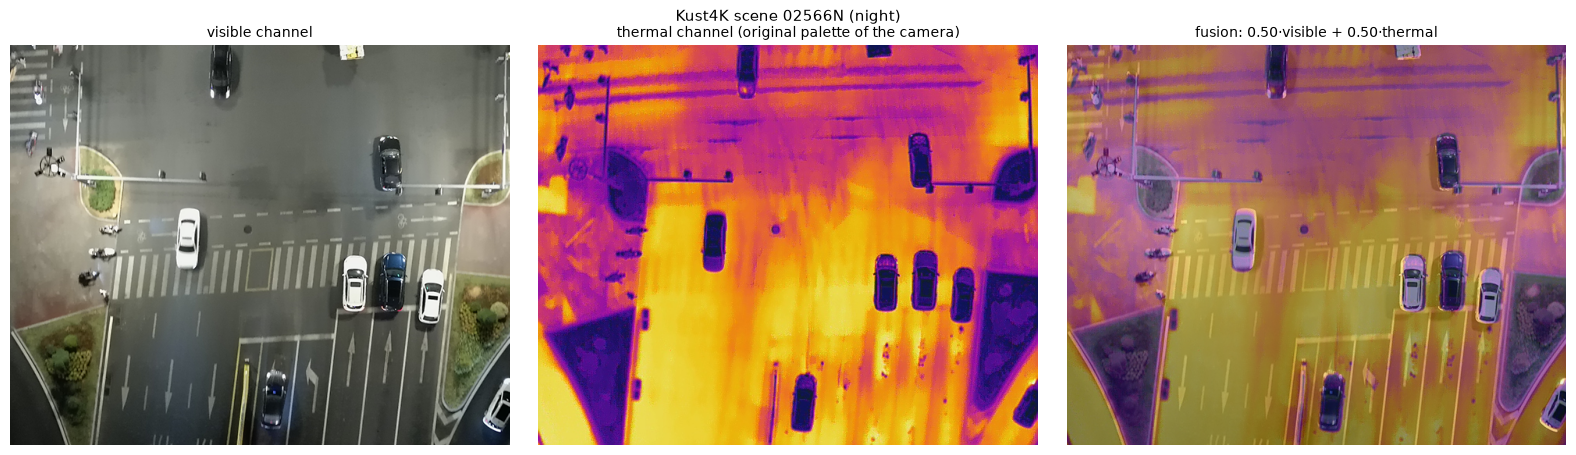

SCR (1) of the objects of scene 02566N: median, (number of objects)


,objects,visible,thermal
object,,,
car,8,1.05,6.56
person,6,0.22,1.99


Median SCR (1) over the 20 scenes (10 day, 10 night):


objects  visible  thermal
object light                           
car    day         53     1.53     1.92
       night       64     0.82     2.81
person day         39     1.33     1.61
       night       41     0.43     3.88

In [5]:
#@title 1.1.1-A Visible and thermal channels of the same scene [auto] { run: "auto", display-mode: "form" }
LIGHT = "night" #@param ["day", "night"]
FRAME_NUMBER = 1 #@param {type:"slider", min:1, max:10, step:1}
THERMAL_VIEW = "original palette of the camera" #@param ["original palette of the camera", "white-hot (grey)", "black-hot (grey)", "ironbow", "rainbow"]
FUSION_WEIGHT = 0.5 #@param {type:"slider", min:0, max:1, step:0.05}
SHOW_LABELS = False #@param {type:"boolean"}

fid = (kust.DAY if LIGHT == "day" else kust.NIGHT)[FRAME_NUMBER - 1]
p = kust.pair(fid)
tg = p["tir_gray"]
if THERMAL_VIEW.startswith("original"):
    tir_view = p["tir"]
elif THERMAL_VIEW.startswith("white"):
    tir_view = aitbc.to_rgb(tg)
elif THERMAL_VIEW.startswith("black"):
    tir_view = aitbc.to_rgb(255 - tg)
else:
    cmap = matplotlib.colormaps["inferno" if THERMAL_VIEW == "ironbow" else "turbo"]
    tir_view = (cmap(tg / 255.0)[..., :3] * 255).astype(np.uint8)
fused = ((1 - FUSION_WEIGHT) * p["rgb"].astype(np.float32) + FUSION_WEIGHT * tir_view.astype(np.float32)).astype(np.uint8)
panels = [p["rgb"].copy(), tir_view.copy(), fused]
if SHOW_LABELS:
    for cid, col in ((7, (0, 229, 255)), (4, (255, 235, 59)), (5, (255, 235, 59)), (3, (255, 235, 59))):
        cnts, _ = cv2.findContours((p["labels"] == cid).astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        for im_ in panels:
            cv2.drawContours(im_, cnts, -1, col, 1, cv2.LINE_AA)
fig, ax = plt.subplots(1, 3, figsize=(16, 4.6))
for a, im_, ti in zip(ax, panels, ("visible channel", f"thermal channel ({THERMAL_VIEW})",
                                   f"fusion: {1 - FUSION_WEIGHT:.2f}·visible + {FUSION_WEIGHT:.2f}·thermal")):
    a.imshow(im_)
    a.set_title(ti, fontsize=10)
    a.axis("off")
fig.suptitle(f"Kust4K scene {fid} ({'night' if p['night'] else 'day'})", fontsize=11)
plt.tight_layout()
plt.show()


def scr_table(pair):
    # SCR (1) of every annotated person and car of a pair in both channels
    rows = []
    others = np.isin(pair["labels"], kust.OBJECTS)
    for name, cid, min_area in (("person", 7, 40), ("car", 4, 300)):
        n, cc, st, _ = cv2.connectedComponentsWithStats((pair["labels"] == cid).astype(np.uint8), 8)
        for i in range(1, n):
            if st[i, 4] >= min_area:
                m = cc == i
                rows.append(dict(scene=pair["id"], light="night" if pair["night"] else "day", object=name,
                                 visible=aitbc.signal_to_clutter(pair["rgb"], m, exclude=others),
                                 thermal=aitbc.signal_to_clutter(pair["tir_gray"], m, exclude=others)))
    return pd.DataFrame(rows)


t = scr_table(p)
if len(t):
    print(f"SCR (1) of the objects of scene {fid}: median, (number of objects)")
    display(t.groupby("object").agg(objects=("visible", "size"), visible=("visible", "median"),
                                    thermal=("thermal", "median")).round(2))
if "SCR_ALL" not in globals():
    SCR_ALL = pd.concat([scr_table(kust.pair(i)) for i in kust.DAY + kust.NIGHT], ignore_index=True)
print("Median SCR (1) over the 20 scenes (10 day, 10 night):")
display(SCR_ALL.groupby(["object", "light"]).agg(objects=("visible", "size"), visible=("visible", "median"),
                                                 thermal=("thermal", "median")).round(2))

### Ground sampling distance and pixels on target

For a camera that looks vertically down from the height $H$, with the horizontal field of view $\alpha$ and the image width of $N$ pixels, the width of the ground strip covered by the image (*footprint*) and the **ground sampling distance** (GSD) are

$$W = 2H\tan\frac{\alpha}{2}, \qquad \mathrm{GSD} = \frac{W}{N} = \frac{2H}{N}\tan\frac{\alpha}{2}, \tag{2}$$

where GSD is the size of the ground area covered by one pixel, m/px; the smaller the GSD, the finer the details in the image. For the thermal camera of HIT-UAV ($\alpha = 25^\circ$, $N = 640$ px) at $H = 100$ m the footprint is $W = 44.3$ m and GSD = 0.069 m/px. For an oblique view the height $H$ in (2) is replaced by the slant range $H/\sin\theta$ to the centre of the image, where $\theta$ is the angle of the optical axis below the horizon (camera angle); the GSD then grows towards the top of the image.

The number of pixels across the **critical dimension** $d_c$ of a target (for a view from above, the width of a vehicle or the shoulders of a person) is

$$n = \frac{d_c}{\mathrm{GSD}}. \tag{3}$$

For the same camera at 100 m a person ($d_c \approx 0.45$ m) occupies $n = 6.5$ px and a car ($d_c \approx 1.8$ m) $n = 26$ px.

The **Johnson criteria** relate $n$ to the level of the visual task. For a 50 % probability of success an observer needs about 1 cycle (≈ 2 px) across the critical dimension for **detection** (an object is present), 4 cycles (≈ 8 px) for **recognition** (the class of the object: vehicle or person) and 6.4 cycles (≈ 13 px) for **identification** (the type of the object). One cycle is a pair of a dark and a bright line, therefore it needs at least two pixels. The criteria were obtained for human observers; neural-network detectors show a similar dependence: targets smaller than 10–15 px are the main source of missed detections.

In annotated real images a box is larger than $d_c/\mathrm{GSD}$ by a margin of several pixels: the blur of the optics, the thermal "halo" around a warm object and the margin left by the annotator. Block 1.1.1-B estimates this margin from the 24 899 annotated objects of HIT-UAV.

### Block 1.1.1-B. Pixels on target: formula (3) and real thermal images [auto]

**Purpose.** To estimate from which altitude a target can still be detected, recognised or identified, and to compare formula (3) with the sizes of objects in real thermal images of HIT-UAV.

**Parameters.**
- `TARGET` — class of the target; `CRITICAL_DIM_M` — critical dimension, m (0 = default: person 0.45 m, bicycle 0.6 m, car 1.8 m).
- `CAMERA_ANGLE_DEG` — camera angle of the HIT-UAV images in the lower panels (90° = vertical view).
- `HFOV_DEG`, `IMAGE_WIDTH_PX`, `ALTITUDE_M` — camera and altitude of the calculator (defaults: thermal camera of HIT-UAV).

**Output.**
1. Calculator: footprint, GSD (2), pixels on target (3), the achievable task level and the maximum altitudes of detection, recognition and identification.
2. Real image chips: the same class at flight altitudes of 60–130 m, with the width of the annotated box.
3. Measured width of the annotated boxes (median and interquartile range over all images of the selected camera angle) against formula (3) and against the model $n = d/\mathrm{GSD} + m$ fitted to the annotations, where $d$ is the effective size of the object, m, and $m$ is the margin of the box, px.

**What to observe.** $n$ decreases in inverse proportion to the altitude. The measured boxes follow the trend of (3) but are wider by a margin of several pixels; at an oblique camera angle the slant range is longer and the objects are smaller. A person at 120–130 m occupies about 5 px across the shoulders: detection is possible, recognition by the shape is not. The scatter of the measured widths is caused by the pose of the objects, by the annotation and by the difference between the recorded flight altitude and the height of the camera above the observed surface. By day a person may be darker than the sun-heated ground: the thermal contrast changes its sign.

,Value
"Footprint width W, m (2)",44.3
"GSD, m/px (2)",0.0693
"Critical dimension of the target, m",0.45
Pixels on target n (3),6.5
Achievable task level,detection
"Maximum altitude of detection, m",325
"Maximum altitude of recognition, m",81
"Maximum altitude of identification, m",51


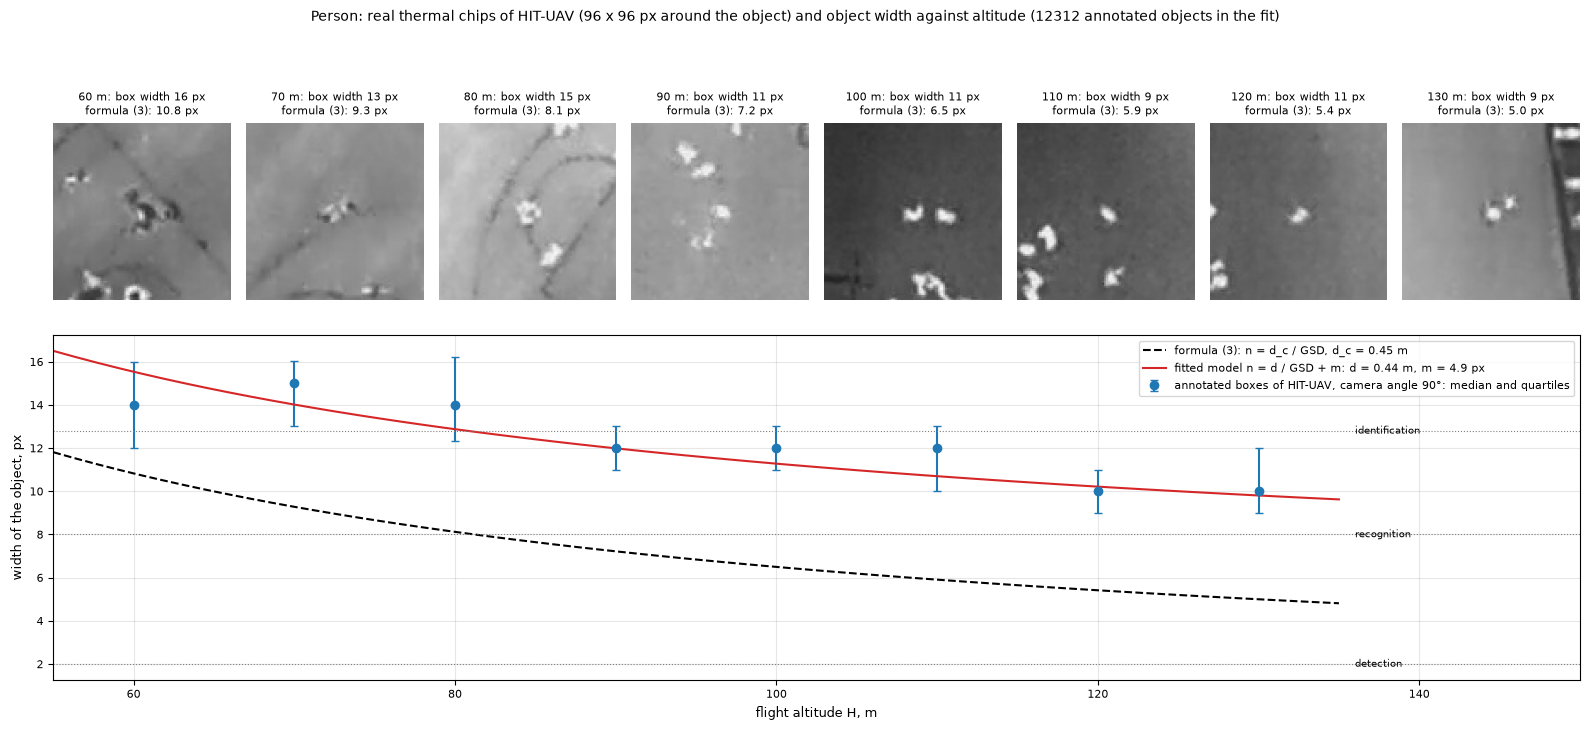

In [6]:
#@title 1.1.1-B Pixels on target: formula and real thermal images [auto] { run: "auto", display-mode: "form" }
TARGET = "Person" #@param ["Person", "Car", "Bicycle"]
CRITICAL_DIM_M = 0.0 #@param {type:"number"}
CAMERA_ANGLE_DEG = 90 #@param {type:"slider", min:30, max:90, step:10}
#@markdown Camera of the calculator (defaults: Zenmuse XT2 thermal camera of HIT-UAV):
HFOV_DEG = 25 #@param {type:"slider", min:5, max:120, step:1}
IMAGE_WIDTH_PX = "640" #@param ["640", "960", "1280", "1920", "3840"]
ALTITUDE_M = 100 #@param {type:"slider", min:10, max:1500, step:10}

N_px = int(IMAGE_WIDTH_PX)
d_c = CRITICAL_DIM_M if CRITICAL_DIM_M > 0 else {"Person": 0.45, "Bicycle": 0.6, "Car": 1.8}[TARGET]
JOHNSON_PX = {"detection": 2.0, "recognition": 8.0, "identification": 12.8}   # 1, 4 and 6.4 cycles x 2 px
gsd = aitbc.gsd_nadir(ALTITUDE_M, HFOV_DEG, N_px)                            # formula (2)
n = d_c / gsd                                                                 # formula (3)
level = "none (fewer than 2 px)"
for name, need in JOHNSON_PX.items():
    if n >= need:
        level = name
tan_half = math.tan(math.radians(HFOV_DEG) / 2)
H_max = {name: d_c * N_px / (2 * tan_half * need) for name, need in JOHNSON_PX.items()}
display(pd.DataFrame({"Value": [f"{gsd * N_px:.1f}", f"{gsd:.4f}", f"{d_c:.2f}", f"{n:.1f}", level,
                                f"{H_max['detection']:.0f}", f"{H_max['recognition']:.0f}", f"{H_max['identification']:.0f}"]},
                     index=["Footprint width W, m (2)", "GSD, m/px (2)", f"Critical dimension of the target, m",
                            "Pixels on target n (3)", "Achievable task level", "Maximum altitude of detection, m",
                            "Maximum altitude of recognition, m", "Maximum altitude of identification, m"]))

# real chips of the selected class at every flight altitude
obj = hit.objects[(hit.objects.cls == TARGET) & (hit.objects.angle == CAMERA_ANGLE_DEG)]
alts = sorted(obj.altitude.unique())
win = {"Person": 48, "Bicycle": 80, "Car": 140}[TARGET]
fig = plt.figure(figsize=(16, 7.4))
gs = fig.add_gridspec(2, max(len(alts), 1))
if "CHIP_CACHE" not in globals():
    CHIP_CACHE = {}
for j, alt in enumerate(alts):
    key = (TARGET, CAMERA_ANGLE_DEG, alt)
    if key not in CHIP_CACHE:        # the object nearest to the image centre in the image with most objects of the class
        o_alt = obj[obj.altitude == alt]
        f = o_alt.groupby("file").size().sort_values(ascending=False).index[0]
        o_f = o_alt[o_alt.file == f].copy()
        o_f["dc"] = np.hypot((o_f.x1 + o_f.x2) / 2 - 320, (o_f.y1 + o_f.y2) / 2 - 256)
        CHIP_CACHE[key] = (f, o_f.sort_values("dc").iloc[0])
    f, o1 = CHIP_CACHE[key]
    img, _ = hit.load(f)
    cx, cy = int((o1.x1 + o1.x2) / 2), int((o1.y1 + o1.y2) / 2)
    pad = np.pad(img, win, mode="edge")
    chip = pad[cy:cy + 2 * win, cx:cx + 2 * win]
    ax = fig.add_subplot(gs[0, j])
    ax.imshow(cv2.resize(chip, (200, 200), interpolation=cv2.INTER_NEAREST), cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"{alt} m: box width {o1.width_px:.0f} px\nformula (3): {d_c / hit.gsd(alt, CAMERA_ANGLE_DEG):.1f} px",
                 fontsize=8)
    ax.axis("off")
ax = fig.add_subplot(gs[1, :])
g_alt = obj.groupby("altitude")["width_px"]
med, q1, q3 = g_alt.median(), g_alt.quantile(0.25), g_alt.quantile(0.75)
ax.errorbar(med.index, med, yerr=[med - q1, q3 - med], fmt="o", capsize=3, color="C0",
            label=f"annotated boxes of HIT-UAV, camera angle {CAMERA_ANGLE_DEG}°: median and quartiles")
Hs = np.linspace(55, 135, 60)
g_H = np.array([hit.gsd(h, CAMERA_ANGLE_DEG) for h in Hs])
ax.plot(Hs, d_c / g_H, "k--", label=f"formula (3): n = d_c / GSD, d_c = {d_c} m")
if "FIT_CACHE" not in globals():
    FIT_CACHE = {}
if TARGET not in FIT_CACHE:          # least-squares fit of n = d / GSD + m over all annotated objects of the class
    all_cls = hit.objects[hit.objects.cls == TARGET]
    gsd_all = np.array([hit.gsd(a, b) for a, b in zip(all_cls.altitude, all_cls.angle)])
    (d_fit, m_fit), *_ = np.linalg.lstsq(np.c_[1 / gsd_all, np.ones(len(gsd_all))], all_cls.width_px.values, rcond=None)
    FIT_CACHE[TARGET] = (d_fit, m_fit, len(all_cls))
d_fit, m_fit, n_fit = FIT_CACHE[TARGET]
ax.plot(Hs, d_fit / g_H + m_fit, "C3-", label=f"fitted model n = d / GSD + m: d = {d_fit:.2f} m, m = {m_fit:.1f} px")
for name, need in JOHNSON_PX.items():
    ax.axhline(need, color="grey", lw=0.8, ls=":")
    ax.text(136, need, name, fontsize=7, va="center")
ax.set_xlim(55, 150)
ax.set_xlabel("flight altitude H, m")
ax.set_ylabel("width of the object, px")
ax.grid(alpha=0.3)
ax.legend(fontsize=8, loc="upper right")
fig.suptitle(f"{TARGET}: real thermal chips of HIT-UAV ({2 * win} x {2 * win} px around the object) and object width "
             f"against altitude ({n_fit} annotated objects in the fit)", fontsize=10)
plt.tight_layout()
plt.show()

## 1.1.2. Typical applied tasks of computer vision for FPV drones, reconnaissance UAVs and UGVs

The platform defines the viewing geometry, the speed of change of the scene and the available computing power, and therefore the set of practical tasks.

- **FPV drone** — low altitude, forward-looking oblique camera with a wide field of view, high speed, analog or digital video link, minimum on-board computing:
  - detection of objects and highlighting them for the operator;
  - tracking of a selected object and holding it in the frame when the video link degrades;
  - stabilisation and enhancement of degraded frames;
  - visual navigation without satellite signals (visual odometry, matching with a reference map).
- **Reconnaissance UAV** — altitude of 100–3000 m, gimbal with visible and thermal cameras, long flight time:
  - detection, recognition and counting of vehicles, people and fortifications;
  - change detection between flights (new positions, traces of movement);
  - georeferencing of objects (pixel coordinates → map coordinates) and mapping (orthophoto mosaics);
  - tracking of multiple objects and estimation of their motion.
- **Unmanned ground vehicle (UGV)** — camera height of 0.5–3 m, strong perspective, frequent occlusions:
  - semantic segmentation of the traversable area (road, field) and of obstacles (trees, buildings, water);
  - detection of people and vehicles in the direction of movement;
  - visual odometry and simultaneous localisation and mapping (SLAM);
  - following a route or a leading vehicle.

### Block 1.1.2-A. Platform viewpoints and typical outputs on real data [auto]

**Purpose.** To see how the platform defines the view of the scene and which output a typical computer vision task produces for it.

**Parameters.**
- `PLATFORM` — data set of the platform:
  - reconnaissance UAV with a visible camera (VisDrone, oblique views of city streets from 20–100 m, similar to the view of an FPV camera);
  - UAV with a thermal camera (HIT-UAV, 60–130 m, camera angle 30–90°, day and night);
  - UAV with visible and thermal cameras (Kust4K, vertical views of roads, day and night);
  - ground vehicle (GOOSE, front camera at a height of about 2 m).
- `FRAME_NUMBER` — frame of the data set.
- `SHOW_TASK_OUTPUT` — overlay of the output of the typical task: object boxes (VisDrone, HIT-UAV), pixel labels (Kust4K), traversable area (GOOSE).

**Output.** The frame with the manual annotation shown as the output of the task, and a table with the data of the frame.

**Note.** For GOOSE the 64 classes are grouped by the course into *traversable* (asphalt, gravel, soil, low grass, …; green), *conditionally traversable* (high grass, crops, debris; yellow) and *obstacles* (trees, bushes, buildings, vehicles, people, poles, …; red); sky and the bonnet of the own vehicle are not coloured. Open labelled FPV footage is scarce; the oblique low-altitude views of VisDrone and HIT-UAV (camera angle 30°) are close to the view of an FPV camera.

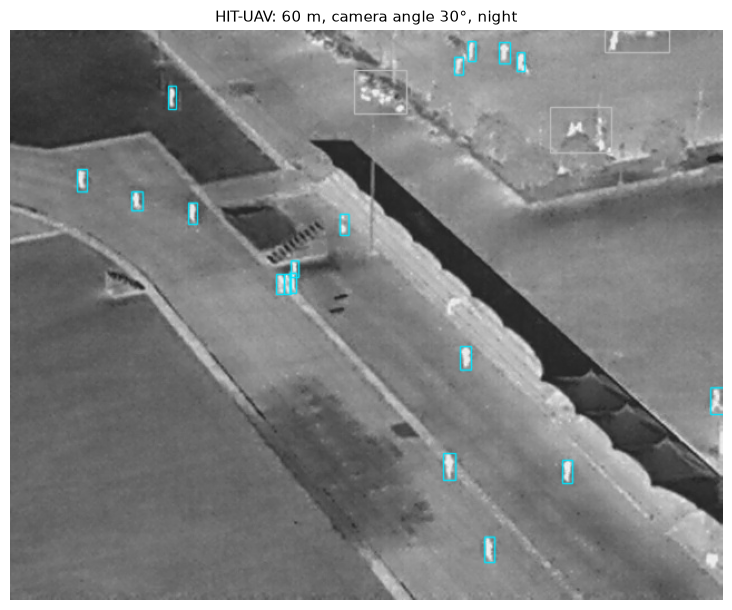

,Value
Image,1_60_30_0_00047.jpg
"Flight altitude, m",60
"Camera angle, deg",30
Time,night
"GSD at the image centre, m/px (2)",0.083
Annotated objects,21
"Median size of persons, px",8
Typical task,search for people and vehicles day and night


Annotation of the frame: Person: 18, DontCare: 3


In [7]:
#@title 1.1.2-A Platform viewpoints and typical outputs on real data [auto] { run: "auto", display-mode: "form" }
PLATFORM = "UAV, thermal camera (HIT-UAV)" #@param ["Reconnaissance UAV, visible camera (VisDrone)", "UAV, thermal camera (HIT-UAV)", "UAV, visible + thermal cameras (Kust4K)", "Ground vehicle (GOOSE)"]
FRAME_NUMBER = 1 #@param {type:"slider", min:1, max:8, step:1}
SHOW_TASK_OUTPUT = True #@param {type:"boolean"}

info = {}
if PLATFORM.startswith("Reconnaissance"):
    name = vis.CURATED[FRAME_NUMBER - 1]
    img, objs = vis.load(name)
    shown = aitbc.draw_boxes(img, objs, vis.COLORS, labels=False) if SHOW_TASK_OUTPUT else img
    hts = [o["box"][3] - o["box"][1] for o in objs]
    info = {"Image": name, "Size, px": f"{img.shape[1]} x {img.shape[0]}", "Annotated objects": len(objs),
            "Median box height, px": f"{np.median(hts):.0f}", "Boxes lower than 20 px": f"{np.mean(np.array(hts) < 20) * 100:.0f} %",
            "Typical task": "detection of people and vehicles"}
    counts = pd.Series([o["cls"] for o in objs]).value_counts()
    title = f"VisDrone: {len(objs)} annotated objects"
elif PLATFORM.startswith("UAV, thermal"):
    f = hit.EXAMPLES[FRAME_NUMBER - 1]
    img, objs = hit.load(f)
    r = hit.images.set_index("file").loc[f]
    shown = aitbc.draw_boxes(img, objs, hit.COLORS, labels=False) if SHOW_TASK_OUTPUT else aitbc.to_rgb(img)
    w = [min(o["box"][2] - o["box"][0], o["box"][3] - o["box"][1]) for o in objs if o["cls"] == "Person"]
    info = {"Image": f, "Flight altitude, m": r.altitude, "Camera angle, deg": r.angle,
            "Time": "night" if r.night else "day", "GSD at the image centre, m/px (2)": f"{hit.gsd(r.altitude, r.angle):.3f}",
            "Annotated objects": len(objs), "Median size of persons, px": f"{np.median(w):.0f}" if w else "-",
            "Typical task": "search for people and vehicles day and night"}
    counts = pd.Series([o["cls"] for o in objs]).value_counts()
    title = f"HIT-UAV: {r.altitude} m, camera angle {r.angle}°, {'night' if r.night else 'day'}"
elif PLATFORM.startswith("UAV, visible"):
    fid = kust.DAY[FRAME_NUMBER - 1] if FRAME_NUMBER <= 4 else kust.NIGHT[FRAME_NUMBER - 5]
    p = kust.pair(fid)
    if SHOW_TASK_OUTPUT:
        col = aitbc.colorize(p["labels"], kust.COLORS)
        mask = p["labels"] > 0
        shown = np.hstack([aitbc.overlay(p["rgb"], col, 0.5, mask), aitbc.overlay(p["tir"], col, 0.5, mask)])
    else:
        shown = np.hstack([p["rgb"], p["tir"]])
    share = np.bincount(p["labels"].ravel(), minlength=9) / p["labels"].size
    info = {"Scene": fid, "Time": "night" if p["night"] else "day", "Size, px": "640 x 512 (each channel)",
            "Typical task": "segmentation of roads, buildings, vegetation, vehicles and people"}
    counts = pd.Series({kust.CLASSES[i]: f"{share[i] * 100:.1f} %" for i in range(1, 9) if share[i] > 0})
    title = f"Kust4K scene {fid}: visible (left) and thermal (right), pixel labels"
else:
    lm = goose.CURATED[FRAME_NUMBER - 1]
    img, lab = goose.load(lm)
    tv = goose.traversability(lab)
    if SHOW_TASK_OUTPUT:
        col = np.zeros_like(img)
        col[tv == 1], col[tv == 2], col[tv == 3] = (0, 200, 0), (255, 200, 0), (230, 30, 30)
        shown = aitbc.overlay(img, col, 0.45, tv > 0)
    else:
        shown = img
    valid = tv > 0
    info = {"Scene": lm.split("/")[2], "Size, px": f"{img.shape[1]} x {img.shape[0]} (reduced 2 times)",
            "Traversable": f"{(tv == 1).sum() / valid.sum() * 100:.0f} %", "Conditionally traversable": f"{(tv == 2).sum() / valid.sum() * 100:.0f} %",
            "Obstacles": f"{(tv == 3).sum() / valid.sum() * 100:.0f} %", "Typical task": "traversable area and obstacles in the direction of movement"}
    ids, cnt = np.unique(lab, return_counts=True)
    top = sorted(zip(cnt, ids), reverse=True)[:8]
    counts = pd.Series({goose.names[int(i)]: f"{c / lab.size * 100:.1f} %" for c, i in top})
    title = "GOOSE: traversable (green), conditionally traversable (yellow), obstacles (red)"
fig, ax = plt.subplots(figsize=(15, 6.2))
ax.imshow(shown, cmap="gray")
ax.set_title(title, fontsize=11)
ax.axis("off")
plt.tight_layout()
plt.show()
display(pd.DataFrame({"Value": list(info.values())}, index=list(info.keys())))
print("Annotation of the frame:", ", ".join(f"{k}: {v}" for k, v in counts.items()))

## 1.1.3. Classification, detection, segmentation and tracking

The four basic tasks differ by the question they answer and by the structure of the output data.

| Task | Question | Output for one frame | Typical models | Typical quality metrics |
|---|---|---|---|---|
| Image (patch) classification | *What* is in the image or in its part? | one class label and its probability | ResNet, MobileNet, EfficientNet | accuracy, precision, recall, F1 |
| Object detection | *Which* objects and *where*? | list of boxes $[x_1, y_1, x_2, y_2]$, class, confidence | YOLO, SSD, Faster R-CNN, DETR | IoU, precision, recall, mAP |
| Semantic segmentation | *Which class* does every pixel belong to? | label map of the image size $H \times W$ | U-Net, DeepLab, SegFormer | pixel accuracy, IoU per class, mIoU |
| Instance segmentation | Which pixels belong to *each* object? | one mask and one class per object | Mask R-CNN, YOLO-seg | mask AP |
| Object tracking | *Where* does each object move? | boxes with a persistent identifier in every frame | SORT, ByteTrack, BoT-SORT | MOTA, IDF1, HOTA, identity switches |

The tasks form a sequence of growing detail and growing cost of annotation: a class label of an image takes seconds, a box takes several seconds per object, a pixel mask takes minutes per image. Tracking adds the time dimension: a detector processes every frame separately, a tracker links the detections of successive frames into trajectories and keeps the identifier of an object when it is briefly hidden.

### Block 1.1.3-A. Four tasks on real data [auto]

**Purpose.** To see the difference between the four tasks on real UAV data and to inspect the data structures that each task returns.

**Parameters.**
- `SCENE` — Kust4K scene for panels (a)–(c) (visible image with pixel labels); `TILE_PX` — size of the square patch for patch classification; `ALPHA` — opacity of the segmentation overlay.
- `TRACK_VIDEO`, `TRACK_FRAMES` — thermal video of HIT-UAV and the number of its frames for panel (d).

**Output.** (a) patch classification — every tile receives the label of the object class that occupies most of its pixels; (b) detection — boxes of the objects; (c) semantic segmentation — the class of every pixel; (d) tracking — trajectories of moving warm objects in the thermal video. Below the panels the outputs are printed in the form in which real models return them.

**Important.** Panels (a)–(c) are produced from the manual pixel labels of Kust4K and show the *format* of the results: boxes are the bounding rectangles of connected labelled regions, therefore objects that touch each other merge into one box. Panel (d) is a result of real processing of the video: the classical hot-spot detector of block 1.1.4-A, compensation of the camera motion (phase correlation of successive frames) and a nearest-neighbour tracker; only tracks that last at least 12 frames and move at least 2 m are drawn. Trained detectors and the ByteTrack tracker are the subject of Topic 5.

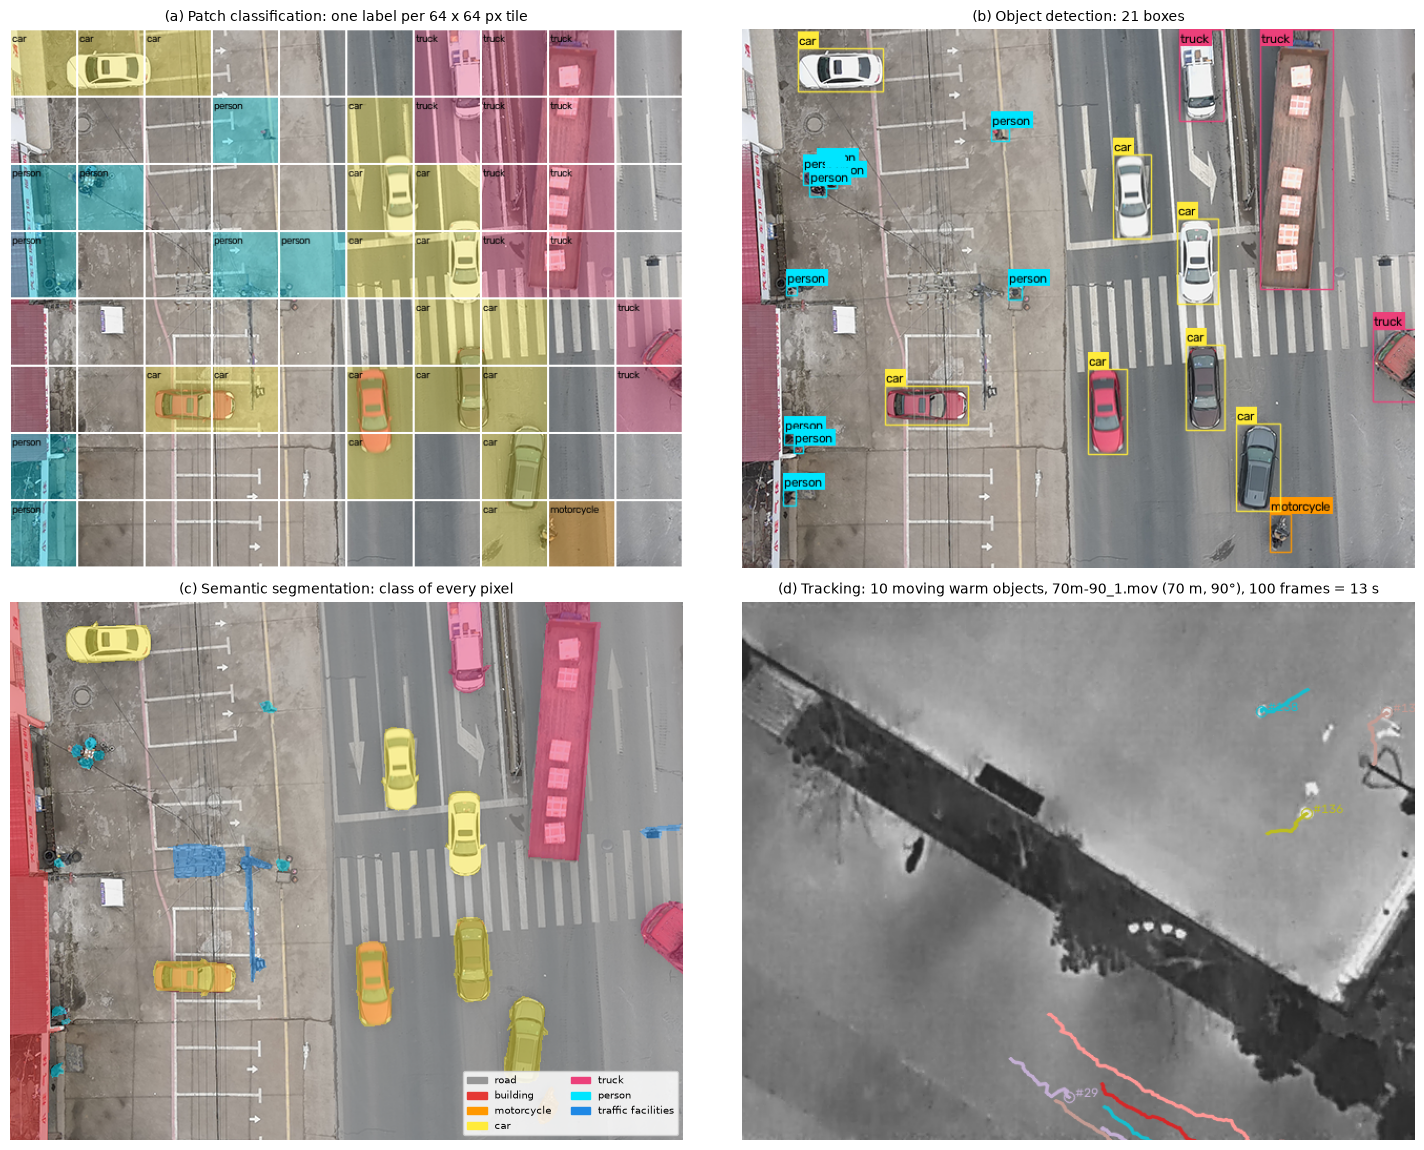

(a) CLASSIFICATION: grid of labels (8, 10); tiles per label: {'background': 41, 'car': 18, 'motorcycle': 1, 'person': 8, 'truck': 12}

(b) DETECTION: array N x 5 = [x1, y1, x2, y2, class_id], N = 21 (a trained detector adds a sixth column: confidence)
[[502. 461. 522. 497.   3.]
 [ 53.  18. 134.  59.   4.]
 [353. 119. 389. 199.   4.]
 [414. 180. 453. 261.   4.]
 [422. 300. 459. 381.   4.]]

(c) SEGMENTATION: label map (512, 640) uint8; share of pixels: unlabelled 40.8 %, road 43.3 %, building 4.4 %, motorcycle 0.1 %, car 5.2 %, truck 5.1 %, person 0.3 %, traffic facilities 0.9 %

(d) TRACKING: 28.6 detections per frame, 22 ms per frame on this runtime; rows (frame, track_id, x, y) of the moving tracks:


,frame,track_id,x,y
6,0,7,278.5,78.5
44,1,7,280.5,78.5
69,2,7,284.0,80.5
95,3,7,285.5,82.0
120,4,7,287.5,84.0
145,5,7,290.0,86.0
169,6,7,292.0,88.5
193,7,7,293.5,91.0
220,8,7,291.5,92.5
245,9,7,298.0,94.5


In [8]:
#@title 1.1.3-A Classification, detection, segmentation and tracking on real data [auto] { run: "auto", display-mode: "form" }
SCENE = "00720D" #@param ["00720D", "00031D", "00851D", "00580D", "02293D", "02566N", "02867N", "03780N", "04004N"]
TILE_PX = 64 #@param {type:"slider", min:32, max:128, step:16}
ALPHA = 0.5 #@param {type:"slider", min:0.1, max:1.0, step:0.05}
TRACK_VIDEO = "70m-90_1.mov" #@param ["70m-90_1.mov", "60m-30_1.mov", "60m-40_3.mov", "130m-60_3.mov", "120m-30_3.mov"]
TRACK_FRAMES = 100 #@param {type:"slider", min:20, max:240, step:10}

p = kust.pair(SCENE)
img, lab = p["rgb"], p["labels"]
# (a) patch classification
grid = aitbc.patch_labels(lab, TILE_PX, kust.OBJECTS, kust.CLASSES, min_px=10)
a_img = img.copy()
for r in range(grid.shape[0]):
    for c in range(grid.shape[1]):
        x0, y0 = c * TILE_PX, r * TILE_PX
        if grid[r, c] != "background":
            col = tuple(int(v) for v in kust.COLORS[kust.CLASSES.index(grid[r, c])])
            ov = a_img.copy()
            cv2.rectangle(ov, (x0, y0), (x0 + TILE_PX - 1, y0 + TILE_PX - 1), col, -1)
            a_img = cv2.addWeighted(ov, 0.35, a_img, 0.65, 0)
            cv2.putText(a_img, grid[r, c][:10], (x0 + 2, y0 + 12), cv2.FONT_HERSHEY_SIMPLEX, 0.35, (0, 0, 0), 1, cv2.LINE_AA)
        cv2.rectangle(a_img, (x0, y0), (x0 + TILE_PX - 1, y0 + TILE_PX - 1), (255, 255, 255), 1)
# (b) detection: boxes of connected labelled regions
boxes = aitbc.boxes_from_labels(lab, kust.OBJECTS, kust.CLASSES, min_area=30)
b_img = aitbc.draw_boxes(img, boxes, {n: tuple(int(v) for v in kust.COLORS[i]) for i, n in enumerate(kust.CLASSES)})
# (c) semantic segmentation
c_img = aitbc.overlay(img, aitbc.colorize(lab, kust.COLORS), ALPHA, lab > 0)
# (d) tracking in a thermal video (cached: recomputed only when the video or the number of frames changes)
key = (TRACK_VIDEO, TRACK_FRAMES)
if "TRACK_CACHE" not in globals():
    TRACK_CACHE = {}
if key not in TRACK_CACHE:
    frames, fps = aitbc.read_video(hit.video(TRACK_VIDEO), max_frames=TRACK_FRAMES)
    alt, ang = hit.video_geometry(TRACK_VIDEO)
    t0 = time.time()
    tr, moving, rows, n_det = aitbc.track_warm_objects(frames, hit.gsd(alt, ang), fps)
    TRACK_CACHE[key] = (frames[-1], moving, rows, n_det, fps, alt, ang, (time.time() - t0) / len(frames))
last, moving, rows, n_det, fps, alt, ang, t_frame = TRACK_CACHE[key]
d_img = aitbc.to_rgb(aitbc.gray(last)).copy()
palette = (plt.cm.tab20(np.linspace(0, 1, 20))[:, :3] * 255).astype(int)
for tid, pts in moving.items():
    col = tuple(int(v) for v in palette[tid % 20])
    cv2.polylines(d_img, [np.round(pts).astype(np.int32).reshape(-1, 1, 2)], False, col, 2, cv2.LINE_AA)
    cv2.circle(d_img, tuple(int(v) for v in pts[-1]), 5, col, 1, cv2.LINE_AA)
    cv2.putText(d_img, f"#{tid}", (int(pts[-1][0]) + 6, int(pts[-1][1])), cv2.FONT_HERSHEY_SIMPLEX, 0.4, col, 1, cv2.LINE_AA)

fig, axes = plt.subplots(2, 2, figsize=(15, 11.6))
panels = [(a_img, f"(a) Patch classification: one label per {TILE_PX} x {TILE_PX} px tile"),
          (b_img, f"(b) Object detection: {len(boxes)} boxes"),
          (c_img, "(c) Semantic segmentation: class of every pixel"),
          (d_img, f"(d) Tracking: {len(moving)} moving warm objects, {TRACK_VIDEO} ({alt} m, {ang}°), "
                  f"{TRACK_FRAMES} frames = {TRACK_FRAMES / fps:.0f} s")]
for ax, (im_, ti) in zip(axes.ravel(), panels):
    ax.imshow(im_)
    ax.set_title(ti, fontsize=10)
    ax.axis("off")
present = sorted(set(np.unique(lab).tolist()) - {0})
aitbc.legend(axes[1, 0], [kust.CLASSES[i] for i in present], [kust.COLORS[i] for i in present], ncol=2)
plt.tight_layout()
plt.show()

vals, cnts = np.unique(grid, return_counts=True)
print(f"(a) CLASSIFICATION: grid of labels {grid.shape}; tiles per label:", dict(zip(vals.tolist(), cnts.tolist())))
det = np.array([b["box"] + [b["class_id"]] for b in boxes]).reshape(-1, 5)
print(f"\n(b) DETECTION: array N x 5 = [x1, y1, x2, y2, class_id], N = {len(det)} "
      "(a trained detector adds a sixth column: confidence)")
with np.printoptions(precision=0, suppress=True):
    print(det[:5])
ids, cnt = np.unique(lab, return_counts=True)
print(f"\n(c) SEGMENTATION: label map {lab.shape} {lab.dtype}; share of pixels:",
      ", ".join(f"{kust.CLASSES[i]} {c / cnt.sum() * 100:.1f} %" for i, c in zip(ids, cnt)))
print(f"\n(d) TRACKING: {np.mean(n_det):.1f} detections per frame, {t_frame * 1000:.0f} ms per frame on this runtime; "
      "rows (frame, track_id, x, y) of the moving tracks:")
tr_df = pd.DataFrame(rows, columns=["frame", "track_id", "x", "y"])
display(tr_df[tr_df.track_id.isin(list(moving))].sort_values(["track_id", "frame"]).round(1).head(10))

## 1.1.4. Problems of processing video data in combat conditions

The image that reaches a computer vision algorithm differs from the ideal image of the scene. The main groups of factors are:

1. **Platform dynamics.** Vibration of the airframe and propellers, rapid turns, motion blur during the exposure time, rolling-shutter distortion ("jello"), continuous change of scale and viewing angle.
2. **Conditions of observation.** Low light and night, sun glare, haze, fog, rain, dust and smoke; snow and wet surfaces change the thermal contrast; in the morning and evening the temperatures of objects and background become equal (*thermal crossover*).
3. **Countermeasures.** Camouflage nets and paint, decoys, thermal masking, smoke screens, objects concealed in tree belts and buildings.
4. **Data link.** Analog FPV links under interference and jamming give noise, horizontal tearing, loss of colour and synchronisation; digital links give compression artefacts, lost macroblocks, frozen frames and variable delay.
5. **Computing and time constraints.** Limited power and mass of on-board computers, the need to process 25–60 frames per second, the total delay between the capture of a frame and the action of the operator or autopilot.
6. **Small and fast targets.** From typical altitudes most targets occupy 5–30 px and move several pixels per frame.

Each factor reduces the share of found objects (*recall*) and increases the number of false alarms. The design of an algorithm for a military platform therefore begins with the analysis of the conditions in which the algorithm has to work.

Two measures of the difference between a clean frame $I$ and a degraded frame $K$ of size $M \times N$ are used below. The **peak signal-to-noise ratio** is

$$\mathrm{PSNR} = 10\log_{10}\frac{255^2}{\mathrm{MSE}}, \qquad \mathrm{MSE} = \frac{1}{MN}\sum_{i,j}\left(I_{ij} - K_{ij}\right)^2, \tag{4}$$

where MSE is the mean squared difference of pixel values, and 255 is the maximum value of an 8-bit pixel. PSNR above 35 dB means that the difference is hardly visible, 20–30 dB — clearly visible degradation, below 20 dB — strong degradation. The **structural similarity index** (SSIM) compares local brightness, contrast and structure in small windows; SSIM = 1 for identical images, values below 0.5 mean that the structure of the image is largely lost. SSIM agrees with visual perception better than PSNR: a uniform veil of smoke gives a low PSNR but keeps the structure (high SSIM), while noise and tearing destroy the structure.

### Block 1.1.4-A. Laboratory of video degradations on real frames [auto]

**Purpose.** To model the factors of question 4 on real frames and to estimate their effect on the image and on a classical detector of warm objects.

**Parameters (in the physical order of their action).**
- `PRESET` — ready scenario; `custom` uses the sliders.
- `IMAGE_SOURCE`, `FRAME_NUMBER` — real frame: night thermal image of HIT-UAV with annotated persons, visible image of VisDrone, visible (day) or thermal (night) image of Kust4K, image of the GOOSE ground vehicle, or the own frame of block 0.4.
- Atmosphere: `HAZE` (0–0.9), `SMOKE` (0–1).
- Optics and motion: `MOTION_BLUR_PX` — length of the motion-blur trace, `MOTION_ANGLE_DEG` — its direction, `ROLLING_SHUTTER_PX` — amplitude of the rolling-shutter distortion.
- Sensor: `LIGHT_LEVEL` (1 = no change, 0.01 = night without illumination; visible images only), `NOISE_SIGMA` — standard deviation of additive noise, grey levels.
- Resolution and coding: `RESOLUTION_SCALE` — share of the original resolution, `JPEG_QUALITY` (100 = no compression).
- Radio link: `ANALOG_INTERFERENCE` (0–1), `PACKET_LOSS` — share of lost macroblocks.

**Output.** The clean and the degraded frame, PSNR (4) and SSIM, and the sharpness (variance of the Laplacian). For the HIT-UAV frames, the result of the hot-spot detector (white top-hat filter, threshold, connected components, size limits from the GSD of the frame) on both frames, compared with the manual annotation: green — found persons, red — missed persons, yellow — false detections.

**Modelled part.** The frames are real; the degradations are models (the formulas are in the library `aitbc`). For the thermal channel haze and smoke are weakened, because long-wave infrared radiation passes thin smoke and haze far better than visible light.

**What to observe.** Smoke and haze hide the visible image but weakly affect the thermal one; motion blur and noise reduce the number of found persons; analog interference destroys the image as a whole, while packet loss damages separate blocks. Even on the clean night frame the classical detector misses some persons and produces false detections on warm details of the background (lamps, parts of vehicles, warm spots of the ground). The sharpness (variance of the Laplacian) falls with blur but grows with noise and compression artefacts: one number does not describe the quality of a frame, therefore PSNR, SSIM and the result of the detector are shown together.

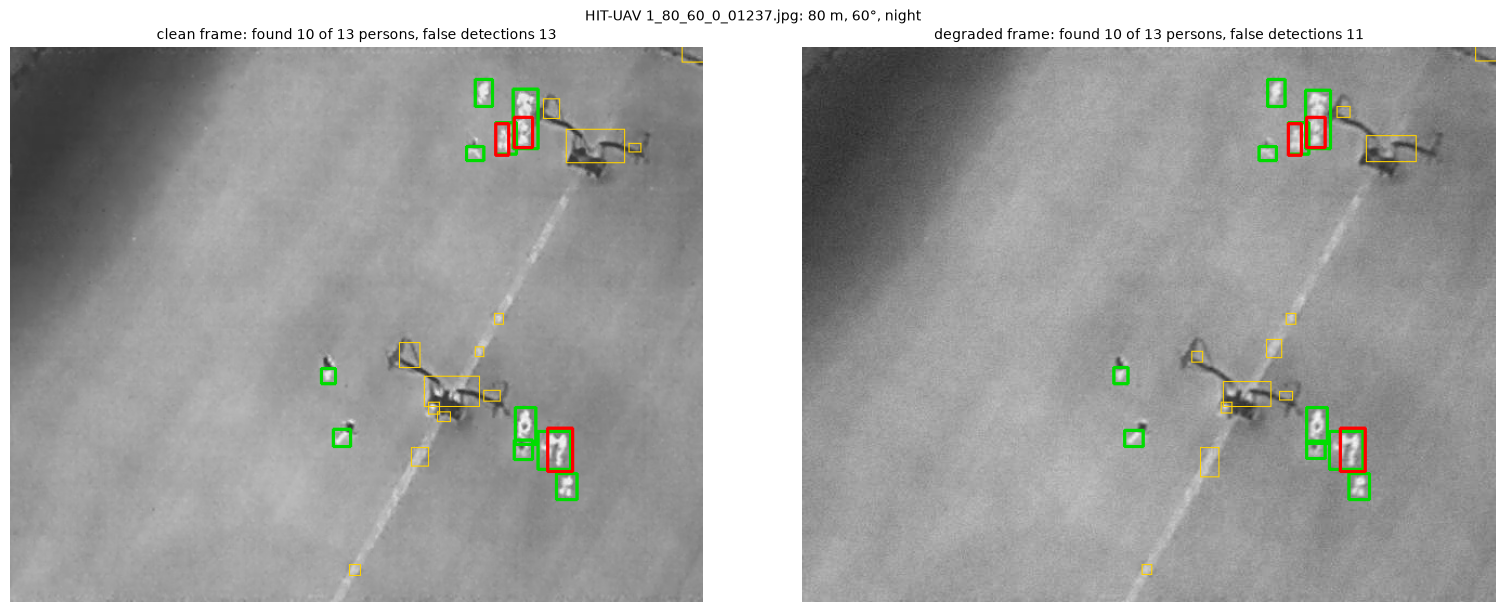

Channel: thermal; applied: {'motion_px': 4, 'motion_angle': 30, 'noise': 6, 'jpeg_quality': 60}
PSNR (4) = 35.2 dB, SSIM = 0.819, sharpness: 30 -> 103


In [9]:
#@title 1.1.4-A Video degradation laboratory on real frames [auto] { run: "auto", display-mode: "form" }
PRESET = "custom (sliders below)" #@param ["custom (sliders below)", "FPV analog link under jamming", "night, visible camera", "smoke screen", "digital link with packet loss", "fast flight, long exposure"]
IMAGE_SOURCE = "HIT-UAV thermal, night (persons annotated)" #@param ["HIT-UAV thermal, night (persons annotated)", "VisDrone visible", "Kust4K visible, day", "Kust4K thermal, night", "GOOSE ground vehicle", "own frame (block 0.4)"]
FRAME_NUMBER = 1 #@param {type:"slider", min:1, max:10, step:1}
#@markdown **Atmosphere**
HAZE = 0.0 #@param {type:"slider", min:0, max:0.9, step:0.05}
SMOKE = 0.0 #@param {type:"slider", min:0, max:1, step:0.05}
#@markdown **Optics and motion**
MOTION_BLUR_PX = 4 #@param {type:"slider", min:0, max:40, step:1}
MOTION_ANGLE_DEG = 30 #@param {type:"slider", min:0, max:180, step:5}
ROLLING_SHUTTER_PX = 0 #@param {type:"slider", min:0, max:30, step:1}
#@markdown **Sensor**
LIGHT_LEVEL = 1.0 #@param {type:"slider", min:0.005, max:1, step:0.005}
NOISE_SIGMA = 6 #@param {type:"slider", min:0, max:60, step:2}
#@markdown **Resolution and coding**
RESOLUTION_SCALE = 1.0 #@param {type:"slider", min:0.1, max:1, step:0.05}
JPEG_QUALITY = 60 #@param {type:"slider", min:5, max:100, step:5}
#@markdown **Radio link**
ANALOG_INTERFERENCE = 0.0 #@param {type:"slider", min:0, max:1, step:0.05}
PACKET_LOSS = 0.0 #@param {type:"slider", min:0, max:0.3, step:0.01}

params = dict(haze_density=HAZE, smoke_density=SMOKE, motion_px=MOTION_BLUR_PX, motion_angle=MOTION_ANGLE_DEG,
              rolling=ROLLING_SHUTTER_PX, light=LIGHT_LEVEL, noise=NOISE_SIGMA, scale=RESOLUTION_SCALE,
              jpeg_quality=JPEG_QUALITY, analog=ANALOG_INTERFERENCE, packet=PACKET_LOSS)
SCENARIOS = {
    "FPV analog link under jamming": dict(motion_px=5, motion_angle=10, analog=0.7, noise=10),
    "night, visible camera": dict(light=0.01, noise=4, jpeg_quality=70),
    "smoke screen": dict(smoke_density=0.75, haze_density=0.2),
    "digital link with packet loss": dict(packet=0.08, jpeg_quality=25),
    "fast flight, long exposure": dict(motion_px=22, motion_angle=0, rolling=8),
}
if PRESET in SCENARIOS:
    params = {k: 0 for k in params} | dict(light=1.0, scale=1.0, jpeg_quality=100) | SCENARIOS[PRESET]

k_ = FRAME_NUMBER - 1
objs, gsd_f, sensor, src_name = None, None, "visible", IMAGE_SOURCE
if IMAGE_SOURCE.startswith("HIT-UAV"):
    f = NIGHT_EVAL[k_ % len(NIGHT_EVAL)]
    clean, objs = hit.load(f)
    r = hit.images.set_index("file").loc[f]
    gsd_f, sensor, src_name = hit.gsd(r.altitude, r.angle), "thermal", f"HIT-UAV {f}: {r.altitude} m, {r.angle}°, night"
elif IMAGE_SOURCE.startswith("VisDrone"):
    clean, _ = vis.load(vis.CURATED[k_ % len(vis.CURATED)])
elif IMAGE_SOURCE.startswith("Kust4K visible"):
    clean = kust.pair(kust.DAY[k_ % 10])["rgb"]
elif IMAGE_SOURCE.startswith("Kust4K thermal"):
    clean, sensor = kust.pair(kust.NIGHT[k_ % 10])["tir"], "thermal"
elif IMAGE_SOURCE.startswith("GOOSE"):
    clean, _ = goose.load(goose.CURATED[k_ % len(goose.CURATED)])
else:
    if OWN_FRAME is None:
        print("Own frame is not loaded (block 0.4); the VisDrone frame is used.")
        clean, _ = vis.load(vis.CURATED[0])
    else:
        clean = OWN_FRAME
degraded = aitbc.degrade(clean, sensor=sensor, seed=5, **params)

panels, titles = [aitbc.to_rgb(clean), aitbc.to_rgb(degraded)], ["clean frame", "degraded frame"]
if objs is not None:
    for i, im_ in enumerate((clean, degraded)):
        boxes, _ = aitbc.detect_warm_objects(im_, gsd_f, k=5.0)
        m = aitbc.match_detections(boxes, objs, ("Person",))
        vis_ = aitbc.to_rgb(aitbc.gray(im_)).copy()
        for b in m["tp"]:
            cv2.rectangle(vis_, (int(b[0]) - 3, int(b[1]) - 3), (int(b[2]) + 3, int(b[3]) + 3), (0, 220, 0), 2)
        for o in m["missed"]:
            x1, y1, x2, y2 = [int(v) for v in o["box"]]
            cv2.rectangle(vis_, (x1 - 2, y1 - 2), (x2 + 2, y2 + 2), (255, 0, 0), 2)
        for b in m["fp"]:
            cv2.rectangle(vis_, (int(b[0]) - 2, int(b[1]) - 2), (int(b[2]) + 2, int(b[3]) + 2), (255, 210, 0), 1)
        n_p = len(m["tp"]) + len(m["missed"])
        panels[i] = vis_
        titles[i] += f": found {len(m['tp'])} of {n_p} persons, false detections {len(m['fp'])}"
fig, ax = plt.subplots(1, 2, figsize=(16, 6.2 * min(1.0, clean.shape[0] / clean.shape[1] * 1.6)))
for a, im_, ti in zip(ax, panels, titles):
    a.imshow(im_)
    a.set_title(ti, fontsize=10)
    a.axis("off")
fig.suptitle(src_name, fontsize=10)
plt.tight_layout()
plt.show()
active = {k: v for k, v in params.items()
          if not ((k in ("light", "scale") and v == 1.0) or (k == "jpeg_quality" and v == 100) or v == 0)}
print(f"Channel: {sensor}; applied: {active if active else 'nothing'}")
print(f"PSNR (4) = {aitbc.psnr(clean, degraded):.1f} dB, SSIM = {aitbc.ssim(clean, degraded):.3f}, "
      f"sharpness: {aitbc.sharpness(clean):.0f} -> {aitbc.sharpness(degraded):.0f}")

### Motion during the exposure and the processing delay

A camera that looks vertically down and moves with the ground speed $V$ during the exposure time $t_e$ produces a motion-blur trace of length

$$b_v = \frac{V\,t_e}{\mathrm{GSD}} \tag{5}$$

px. A visible camera in daylight uses $t_e$ of 0.1–2 ms; an uncooled microbolometer of a thermal camera integrates the scene with a thermal time constant of about 10 ms, which acts as a long exposure. For the thermal camera of HIT-UAV at 100 m (GSD = 0.069 m/px), $V$ = 15 m/s and $t_e$ = 10 ms give $b_v$ = 2.2 px.

Angular vibration of the camera with the angular rate $\omega$, rad/s, adds the trace

$$b_\omega = \omega\, t_e\, f_{px}, \qquad f_{px} = \frac{N}{2\tan(\alpha/2)}, \tag{6}$$

where $f_{px}$ is the focal length expressed in pixels. A trace shorter than about 1 px is not noticeable; above 3–5 px small targets lose their shape.

During the total delay $\tau$ between the capture of a frame and the use of its result (processing, coding, transmission, display), a target that moves with the speed $v$ is displaced in the image by

$$\Delta = \frac{v\,\tau}{\mathrm{GSD}} \tag{7}$$

px. With $v$ = 15 m/s, $\tau$ = 0.2 s and GSD = 0.069 m/px the target moves by 3 m, that is by 43 px: the box shown to the operator lags behind the target.

### Block 1.1.4-B. Motion blur and delay calculator on a real image [auto]

**Purpose.** To estimate the blur (5), (6) and the displacement (7) for the selected flight and camera parameters and to see their effect on a real image of a car.

**Parameters.** `ALTITUDE_M`, `HFOV_DEG`, `IMAGE_WIDTH_PX` — camera geometry (vertical view); `PLATFORM_SPEED_MS` — ground speed of the UAV; `EXPOSURE_MS` — exposure time (thermal time constant for a thermal camera); `ANGULAR_RATE_DEG_S` — angular rate of camera vibration; `TARGET_SPEED_MS` — speed of the target; `DELAY_MS` — total delay of processing and transmission; `FPS` — frame rate.

**Output.** Table of the calculated values and three images of a real car from a vertical HIT-UAV thermal frame taken at 60 m (GSD 0.042 m/px): resampled to the GSD of the calculator, with the calculated blur, and with the box from the delayed result (red) next to the true position (green). The motion is assumed along the horizontal axis of the image.

**Modelled part.** The image is real; the blur and the displacement are applied by the formulas. A GSD finer than 0.042 m/px cannot be shown: the source image is then used at its own resolution.

,Value
"GSD, m/px (2)",0.0693
"focal length f_px, px (6)",1443
"blur from platform motion b_v, px (5)",2.17
"blur from vibration b_w, px (6)",2.52
"total blur, px",3.32
"target displacement during the delay, m",3.00
"target displacement, px (7)",43.3
"target displacement between frames, px",7.2


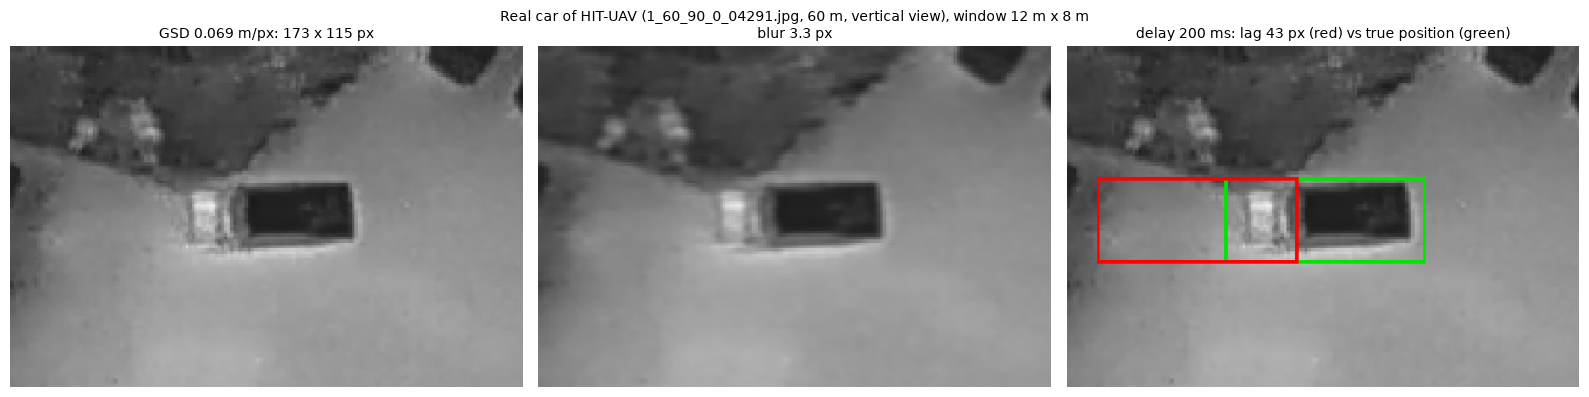

In [10]:
#@title 1.1.4-B Motion blur and delay calculator on a real image [auto] { run: "auto", display-mode: "form" }
ALTITUDE_M = 100 #@param {type:"slider", min:20, max:500, step:5}
HFOV_DEG = 25 #@param {type:"slider", min:10, max:150, step:1}
IMAGE_WIDTH_PX = "640" #@param ["640", "960", "1280", "1920"]
PLATFORM_SPEED_MS = 15 #@param {type:"slider", min:0, max:60, step:1}
EXPOSURE_MS = 10.0 #@param {type:"slider", min:0.1, max:33, step:0.1}
ANGULAR_RATE_DEG_S = 10 #@param {type:"slider", min:0, max:300, step:5}
TARGET_SPEED_MS = 15 #@param {type:"slider", min:0, max:30, step:1}
DELAY_MS = 200 #@param {type:"slider", min:0, max:1000, step:10}
FPS = 30 #@param {type:"slider", min:5, max:120, step:5}

N_px = int(IMAGE_WIDTH_PX)
gsd = aitbc.gsd_nadir(ALTITUDE_M, HFOV_DEG, N_px)                            # (2)
f_px = N_px / (2 * math.tan(math.radians(HFOV_DEG) / 2))                    # (6)
b_v = PLATFORM_SPEED_MS * EXPOSURE_MS / 1000 / gsd                          # (5)
b_w = math.radians(ANGULAR_RATE_DEG_S) * EXPOSURE_MS / 1000 * f_px          # (6)
b_tot = math.hypot(b_v, b_w)
shift_m = TARGET_SPEED_MS * DELAY_MS / 1000
shift_px = shift_m / gsd                                                    # (7)
display(pd.DataFrame({"Value": [f"{gsd:.4f}", f"{f_px:.0f}", f"{b_v:.2f}", f"{b_w:.2f}", f"{b_tot:.2f}",
                                f"{shift_m:.2f}", f"{shift_px:.1f}", f"{TARGET_SPEED_MS / FPS / gsd:.1f}"]},
                     index=["GSD, m/px (2)", "focal length f_px, px (6)", "blur from platform motion b_v, px (5)",
                            "blur from vibration b_w, px (6)", "total blur, px", "target displacement during the delay, m",
                            "target displacement, px (7)", "target displacement between frames, px"]))

if "CAR_CHIP" not in globals():
    cars = hit.objects[(hit.objects.cls == "Car") & (hit.objects.angle == 90) & (hit.objects.altitude == 60)].copy()
    g0 = hit.gsd(60, 90)
    # a horizontal car whose annotated size agrees with 4.5 m x 1.8 m at the recorded altitude
    cars["err"] = abs(cars.length_px * g0 - 4.5) / 4.5 + abs(cars.width_px * g0 - 1.8) / 1.8
    cars["dc"] = np.hypot((cars.x1 + cars.x2) / 2 - 320, (cars.y1 + cars.y2) / 2 - 256)
    cars = cars[(cars.w > 1.8 * cars.h) & (cars.dc < 220)]
    c0 = cars.sort_values("err").iloc[0]
    img0, _ = hit.load(c0.file)
    g0 = hit.gsd(60, 90)
    half_w, half_h = int(6.0 / g0), int(4.0 / g0)                           # window 12 m x 8 m on the ground
    cx, cy = int((c0.x1 + c0.x2) / 2), int((c0.y1 + c0.y2) / 2)
    pad = np.pad(img0, max(half_w, half_h), mode="edge")
    m0 = max(half_w, half_h)
    CAR_CHIP = (pad[cy + m0 - half_h:cy + m0 + half_h, cx + m0 - half_w:cx + m0 + half_w], g0,
                (c0.x1 - cx + half_w, c0.y1 - cy + half_h, c0.x2 - cx + half_w, c0.y2 - cy + half_h), c0.file)
chip, g0, box0, src_file = CAR_CHIP
s = min(1.0, g0 / gsd)                                                       # resampling to the GSD of the calculator
w1, h1 = max(4, int(round(chip.shape[1] * s))), max(4, int(round(chip.shape[0] * s)))
small = cv2.resize(chip, (w1, h1), interpolation=cv2.INTER_AREA)
blurred = aitbc.motion_blur(small, b_tot, angle=0.0)
lag = aitbc.to_rgb(small).copy()
bx = [int(round(v * s)) for v in box0]
cv2.rectangle(lag, (bx[0], bx[1]), (bx[2], bx[3]), (0, 230, 0), 1)
dx = int(round(shift_px))
cv2.rectangle(lag, (bx[0] - dx, bx[1]), (bx[2] - dx, bx[3]), (255, 0, 0), 1)
show_w = 420
fig, ax = plt.subplots(1, 3, figsize=(16, 4.0))
for a, im_, ti in zip(ax, (small, blurred, lag),
                      (f"GSD {max(gsd, g0):.3f} m/px: {w1} x {h1} px", f"blur {b_tot:.1f} px",
                       f"delay {DELAY_MS} ms: lag {shift_px:.0f} px (red) vs true position (green)")):
    a.imshow(cv2.resize(aitbc.to_rgb(im_), (show_w, int(show_w * h1 / w1)), interpolation=cv2.INTER_NEAREST))
    a.set_title(ti, fontsize=10)
    a.axis("off")
fig.suptitle(f"Real car of HIT-UAV ({src_file}, 60 m, vertical view), window 12 m x 8 m", fontsize=10)
plt.tight_layout()
plt.show()
if gsd < g0:
    print(f"The GSD of the calculator ({gsd:.3f} m/px) is finer than that of the source image ({g0:.3f} m/px); "
          "the image is shown at the source resolution.")

### Block 1.1.4-C. Detector recall versus the level of degradation on real annotated frames

**Purpose.** To obtain a quantitative dependence of the quality of a classical detector on one degradation factor, using real night thermal frames with manual annotation of persons.

**Parameters.** `FACTOR` — the degradation that is varied; `N_FRAMES` — number of night HIT-UAV frames (about 0.1 s of computation per frame and level).

**Output.** The share of found persons (*recall*) and the share of correct detections among all detections (*precision*) for ten levels of the factor; both metrics are studied in detail in Topic 4. Detections inside boxes of other annotated objects (cars, bicycles) are not counted as false.

**What to observe.** The curves show the level of the factor at which the detector stops being useful; this level is a requirement to the preprocessing (Topic 2) or to the data link. Already without degradation the precision of the classical detector is low: warm details of the background are taken for persons. This limitation of hand-made rules is the reason for learned detectors (Topics 4 and 5).

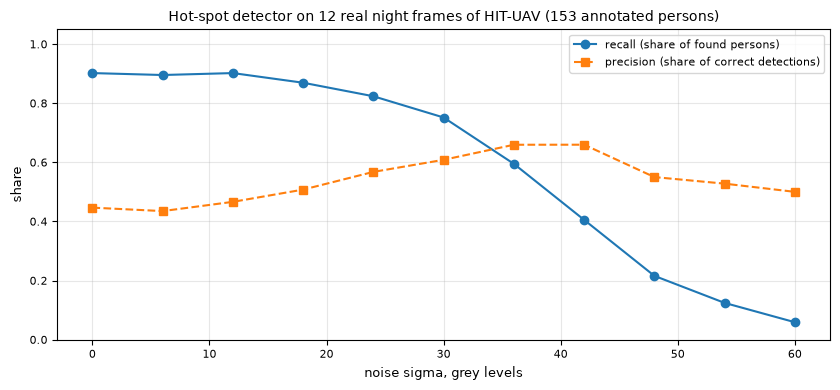

level,0,6,12,18,24,30,36,42,48,54,60
recall,0.902,0.895,0.902,0.869,0.824,0.752,0.595,0.405,0.216,0.124,0.059
precision,0.447,0.435,0.466,0.508,0.568,0.608,0.659,0.660,0.550,0.528,0.500


In [11]:
#@title 1.1.4-C Detector recall versus degradation level on real frames { display-mode: "form" }
FACTOR = "noise sigma, grey levels" #@param ["noise sigma, grey levels", "motion blur, px", "JPEG quality", "analog interference", "resolution scale"]
N_FRAMES = 12 #@param {type:"slider", min:4, max:20, step:1}

LEVELS = {"noise sigma, grey levels": ("noise", np.arange(0, 61, 6)),
          "motion blur, px": ("motion_px", np.arange(0, 31, 3)),
          "JPEG quality": ("jpeg_quality", np.array([100, 80, 60, 40, 30, 20, 15, 10, 7, 5])),
          "analog interference": ("analog", np.round(np.linspace(0, 1, 11), 2)),
          "resolution scale": ("scale", np.array([1.0, 0.8, 0.6, 0.5, 0.4, 0.3, 0.25, 0.2, 0.15, 0.1]))}
key, levels = LEVELS[FACTOR]
meta = hit.images.set_index("file")
data = [(hit.load(f), hit.gsd(meta.loc[f].altitude, meta.loc[f].angle)) for f in NIGHT_EVAL[:N_FRAMES]]
recall, precision = [], []
for lv in levels:
    tp = fp = n = 0
    for i, ((img, objs), g_) in enumerate(data):
        im_ = aitbc.degrade(img, sensor="thermal", seed=i, **{key: float(lv)})
        b, _ = aitbc.detect_warm_objects(im_, g_, k=5.0)
        m = aitbc.match_detections(b, objs, ("Person",))
        tp, fp, n = tp + len(m["tp"]), fp + len(m["fp"]), n + len(m["tp"]) + len(m["missed"])
    recall.append(tp / max(n, 1))
    precision.append(tp / max(tp + fp, 1))
fig, ax = plt.subplots(figsize=(8.5, 4))
ax.plot(levels, recall, "o-", label="recall (share of found persons)")
ax.plot(levels, precision, "s--", label="precision (share of correct detections)")
if key in ("jpeg_quality", "scale"):
    ax.invert_xaxis()
ax.set_xlabel(FACTOR + (" (degradation grows to the right)" if key in ("jpeg_quality", "scale") else ""))
ax.set_ylabel("share")
ax.set_ylim(0, 1.05)
ax.grid(alpha=0.3)
ax.legend()
ax.set_title(f"Hot-spot detector on {N_FRAMES} real night frames of HIT-UAV ({n} annotated persons)", fontsize=10)
plt.tight_layout()
plt.show()
display(pd.DataFrame({"level": levels, "recall": np.round(recall, 3), "precision": np.round(precision, 3)}).set_index("level").T)

### Summary of Lesson 1.1

- Computer vision is the stage of an electro-optical system that converts images into information about objects: presence, class, location and motion. It is executed on board or at the ground control station.
- The visible and the thermal channels complement each other: on the real Kust4K pairs the signal-to-clutter ratio (1) of persons at night is several times higher in the thermal channel; the sign of the thermal contrast depends on the background (persons are darker than the warm asphalt at night, brighter than cold ground).
- The ground sampling distance (2) and the number of pixels on a target (3) define the achievable task level — detection, recognition or identification (Johnson criteria). Real annotated boxes follow (3) with a margin of several pixels.
- Classification, detection, segmentation and tracking differ by the structure of their output: label, list of boxes, label map, trajectories with identifiers.
- Platform dynamics (5)–(7), conditions of observation, countermeasures, degradation of the data link and real-time constraints are considered from the beginning of the design of an algorithm; their effect is measured by PSNR (4), SSIM and the recall and precision of a detector.

### Control questions
1. Where can computer vision algorithms be executed in a UAV system? Name the advantages and limitations of each option.
2. What information does the thermal channel give that the visible channel does not, and vice versa? Use the SCR table of block 1.1.1-A.
3. Calculate the GSD of the HIT-UAV thermal camera ($\alpha$ = 25°, $N$ = 640 px) at $H$ = 120 m. Can a person (0.45 m) be detected? Recognised? *(GSD = 0.083 m/px, n = 5.4 px: detection is possible, recognition is not; recognition requires H ≤ 81 m.)*
4. Why are the annotated boxes of HIT-UAV wider than $d_c/\mathrm{GSD}$?
5. What is the output of each of the four basic tasks? Which task requires the most expensive annotation, and why?
6. Why does a detector that works well on daytime video fail on video from an analog FPV link under interference?
7. Estimate the displacement of a target in the image caused by a delay of 300 ms ($v$ = 10 m/s, GSD = 0.05 m/px). *(60 px.)*
8. Why does a uniform veil of smoke reduce PSNR strongly but SSIM only slightly?

---
# Lesson 1.2 (Group class). Google Colab tools for processing electro-optical imagery

**Learning questions**
1. Purpose and capabilities of the Google Colab environment for prototyping computer vision algorithms.
2. Using GPU computing resources and integration with Google Drive for storing data sets and models.
3. Overview of the basic libraries for working with images: OpenCV, NumPy, Matplotlib, PyTorch, Ultralytics.
4. Typical project structure for tasks of UAVs and ground robotic platforms.

**Expected outcome.** After the lesson a participant checks the runtime and the accelerator, measures the effect of the GPU on a typical operation, connects Google Drive, explains the role of each basic library and creates the standard project structure that is used in all practical lessons of the course.

## 1.2.1. Purpose and capabilities of Google Colab

Google Colaboratory (Colab) is a cloud service of Jupyter notebooks. A notebook consists of **text cells** (Markdown with formulas) and **code cells** (Python). The code runs on a temporary virtual machine — the **runtime** — in a Google data centre; the participant needs only a browser and a Google account.

Capabilities used in the course:
- preinstalled scientific stack: NumPy, OpenCV, Matplotlib, pandas, scikit-learn, PyTorch;
- installation of additional packages with `!pip install <package>` (for example, Ultralytics in Topic 5);
- accelerators: CPU runtime by default, GPU (for example, NVIDIA T4) or TPU on request;
- files of the session in `/content`; permanent storage in Google Drive;
- **forms** (`#@param`) that turn a code cell into an interactive interface — the mechanism of all blocks of this course;
- shell commands (`!nvidia-smi`, `!ls`) and magic commands (`%time`, `%timeit`, `%%writefile`);
- sharing of notebooks, saving to Google Drive or GitHub, download as `.ipynb` or `.py`.

**Limitations.** The runtime is temporary: files in `/content` and all variables are lost when the session ends or the runtime is restarted. An idle session is disconnected, the maximum length of a session and the GPU time depend on the subscription and are not guaranteed. Restricted or classified data must not be uploaded to a public cloud service.

### Block 1.2.1-A. Runtime report

**Purpose.** To read the resources of the current runtime: processor, memory, disk, GPU and CUDA versions, and the time since the start of the virtual machine.

**Parameters.** None. Run the cell again after changing the runtime type.

In [12]:
#@title 1.2.1-A Runtime report { display-mode: "form" }
rows = [("Python executable", sys.executable)]
cpu_model = platform.processor() or "unknown"
if os.path.exists("/proc/cpuinfo"):
    with open("/proc/cpuinfo") as fh:
        for line in fh:
            if line.startswith("model name"):
                cpu_model = line.split(":", 1)[1].strip()
                break
rows += [("CPU model", cpu_model), ("CPU cores", os.cpu_count())]
try:
    import psutil
    vm = psutil.virtual_memory()
    rows += [("RAM total, GB", f"{vm.total / 1e9:.1f}"), ("RAM available, GB", f"{vm.available / 1e9:.1f}"),
             ("Time since start of the machine, min", f"{(time.time() - psutil.boot_time()) / 60:.0f}")]
except ImportError:
    rows.append(("RAM", "psutil is not installed"))
du = shutil.disk_usage(WORK_DIR)
rows += [("Disk total, GB", f"{du.total / 1e9:.0f}"), ("Disk free, GB", f"{du.free / 1e9:.0f}")]
try:
    out = subprocess.run(["nvidia-smi", "--query-gpu=name,memory.total,memory.used,driver_version",
                          "--format=csv,noheader"], capture_output=True, text=True, timeout=15)
    rows.append(("nvidia-smi", out.stdout.strip() or "no GPU"))
except (FileNotFoundError, subprocess.TimeoutExpired):
    rows.append(("nvidia-smi", "not available (CPU runtime)"))
if torch is not None:
    rows += [("PyTorch CUDA build", str(torch.version.cuda)), ("torch.cuda.is_available()", str(torch.cuda.is_available()))]
display(pd.DataFrame(rows, columns=["Item", "Value"]).set_index("Item"))

,Value
Item,
Python executable,/content/...
CPU model,AMD64
CPU cores,16
"RAM total, GB",29.9
"RAM available, GB",10.0
"Time since start of the machine, min",304
"Disk total, GB",407
"Disk free, GB",45
nvidia-smi,"NVIDIA GeForce RTX 3060 Laptop GPU, 6144 MiB, ..."


### Block 1.2.1-B. Colab forms as an interactive interface [auto]

**Purpose.** To learn the declaration of form fields that is used in all blocks of the course. The code of this cell is shown next to the form.

| Field | Declaration at the end of an assignment |
|---|---|
| slider | `FRAME_NUMBER = 1 #@param {type:"slider", min:1, max:8, step:1}` |
| drop-down list | `DATASET = "HIT-UAV thermal" #@param ["HIT-UAV thermal", "VisDrone visible"]` |
| check box | `SHOW_BOXES = True #@param {type:"boolean"}` |
| integer | `LINE_WIDTH = 1 #@param {type:"integer"}` |
| text | `CAPTION = "UAV frame" #@param {type:"string"}` |

The first line `#@title Name { run: "auto" }` gives the cell a title and makes it run again after every change of a field; the option `display-mode: "form"` hides the code. Lines `#@markdown text` add explanations to the form.

**Task.** Change the fields of the form and compare the declarations in the code with the fields; then add a new field `ZOOM = 1 #@param {type:"slider", min:1, max:4, step:1}` and show only the central part of the frame `img[h//2 - h//(2*ZOOM) : h//2 + h//(2*ZOOM), w//2 - w//(2*ZOOM) : w//2 + w//(2*ZOOM)]`.

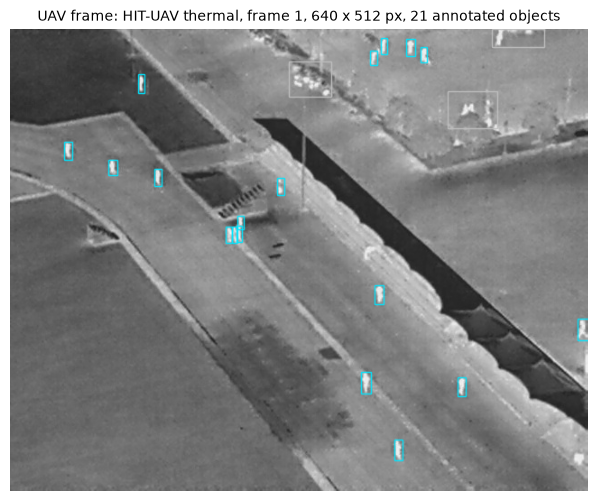

In [13]:
#@title 1.2.1-B Form fields demonstration [auto] { run: "auto" }
DATASET = "HIT-UAV thermal" #@param ["HIT-UAV thermal", "VisDrone visible"]
FRAME_NUMBER = 1 #@param {type:"slider", min:1, max:8, step:1}
SHOW_BOXES = True #@param {type:"boolean"}
LINE_WIDTH = 1 #@param {type:"integer"}
CAPTION = "UAV frame" #@param {type:"string"}

if DATASET.startswith("HIT"):
    img, objs = hit.load(hit.EXAMPLES[FRAME_NUMBER - 1])
    colors = hit.COLORS
else:
    img, objs = vis.load(vis.CURATED[FRAME_NUMBER - 1])
    colors = vis.COLORS
shown = aitbc.draw_boxes(img, objs, colors, labels=False, thickness=max(1, LINE_WIDTH)) if SHOW_BOXES else img
fig, ax = plt.subplots(figsize=(9, 6))
ax.imshow(shown, cmap="gray")
ax.set_title(f"{CAPTION}: {DATASET}, frame {FRAME_NUMBER}, {img.shape[1]} x {img.shape[0]} px, {len(objs)} annotated objects")
ax.axis("off")
plt.show()

## 1.2.2. GPU resources and integration with Google Drive

A central processor (CPU) has a few powerful cores; a graphics processor (GPU) has thousands of simple cores that execute the same operation on many data elements at the same time. Image processing and neural networks consist of exactly such operations (convolution, matrix multiplication), therefore a GPU accelerates them by tens of times. The gain is reduced by the time of copying the data between the main memory and the memory of the GPU: small tasks may run faster on the CPU.

**Enabling the GPU:** *Runtime → Change runtime type → Hardware accelerator: T4 GPU → Save*. The runtime restarts, all variables are lost, and the notebook is run again from Section 0.

The acceleration factor of an operation is

$$k = \frac{t_{\mathrm{CPU}}}{t_{\mathrm{GPU}}}, \tag{8}$$

where $t_{\mathrm{CPU}}$ and $t_{\mathrm{GPU}}$ are the times of the same operation on the CPU and on the GPU; $k > 1$ means that the GPU is faster. The processing rate in frames per second is $1000 / t$ for the time $t$ in milliseconds per frame; real-time processing of a 30 fps video requires $t < 33$ ms for the whole chain of algorithms.

**Google Drive** is the permanent storage of the course: data sets, extracted frames, trained models and results are kept there between sessions. After mounting, Drive is visible as the folder `/content/drive/MyDrive`. Reading many small files from Drive is slow, therefore large data sets are kept as one archive and unpacked to `/content` at the beginning of a session.

### Block 1.2.2-A. CPU versus GPU: Gaussian filtering of a batch of real frames

**Purpose.** To measure the time of the same filtering operation with different libraries and devices and to calculate the acceleration factor (8).

**Parameters.** `RESOLUTION` — frame size (real VisDrone frames are resized to it); `BATCH` — number of frames processed together; `KERNEL` — size of the Gaussian kernel, px; `REPEATS` — number of repetitions for averaging.

**Output.** Table with the time per frame, the processing rate and the acceleration factor relative to PyTorch on the CPU; bar chart.

**What to observe.** OpenCV computes a Gaussian filter as two one-dimensional passes (a separable filter: $2k$ instead of $k^2$ operations per pixel) and is often faster than a direct two-dimensional convolution on the CPU: the algorithm matters as much as the hardware. On the GPU the convolution is fast, but copying the frames to and from the GPU memory takes a considerable part of the time.

,"time per batch, s",ms per frame,frames per second,k relative to PyTorch CPU (8)
Method,,,,
"OpenCV, CPU (separable filter)",0.011,1.361,734.574,13.401
"PyTorch, CPU (2-D convolution)",0.146,18.243,54.815,1.000


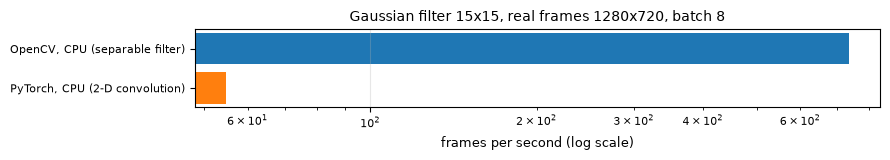

GPU is not available. Runtime → Change runtime type → T4 GPU, then run the notebook again from Section 0.


In [14]:
#@title 1.2.2-A CPU versus GPU: filtering a batch of real frames { display-mode: "form" }
RESOLUTION = "1280x720 (HD)" #@param ["640x512 (thermal)", "1280x720 (HD)", "1920x1080 (Full HD)", "3840x2160 (4K)"]
BATCH = 8 #@param {type:"slider", min:1, max:32, step:1}
KERNEL = 15 #@param {type:"slider", min:3, max:31, step:2}
REPEATS = 3 #@param {type:"slider", min:1, max:10, step:1}

w, h = map(int, RESOLUTION.split()[0].split("x"))
max_batch = max(1, int(1.2e9 / (w * h * 3 * 4)))          # keep the float32 batch below 1.2 GB
if BATCH > max_batch:
    print(f"BATCH is reduced from {BATCH} to {max_batch} to fit into memory.")
    BATCH = max_batch
base = [cv2.resize(vis.load(n)[0], (w, h), interpolation=cv2.INTER_AREA) for n in vis.CURATED[:4]]
frames_u8 = np.stack([base[i % len(base)] for i in range(BATCH)])


def timed(fn, repeats):
    fn()                                   # warm-up run (memory allocation, kernel compilation)
    t0 = time.perf_counter()
    for _ in range(repeats):
        fn()
    return (time.perf_counter() - t0) / repeats


results = [("OpenCV, CPU (separable filter)",
            timed(lambda: [cv2.GaussianBlur(f, (KERNEL, KERNEL), 0) for f in frames_u8], REPEATS))]
if torch is not None:
    sigma = 0.3 * ((KERNEL - 1) * 0.5 - 1) + 0.8          # sigma that OpenCV uses for this kernel size
    g1 = torch.exp(-((torch.arange(KERNEL) - KERNEL // 2) ** 2) / (2 * sigma ** 2))
    g1 = g1 / g1.sum()
    k2 = (g1[:, None] * g1[None, :]).expand(3, 1, KERNEL, KERNEL).contiguous()
    x_cpu = torch.from_numpy(frames_u8).permute(0, 3, 1, 2).float() / 255.0
    conv = lambda x, k: torch.nn.functional.conv2d(x, k, padding=KERNEL // 2, groups=3)
    with torch.no_grad():
        results.append(("PyTorch, CPU (2-D convolution)", timed(lambda: conv(x_cpu, k2), REPEATS)))
        if CUDA_OK:
            x_gpu, k_gpu = x_cpu.cuda(), k2.cuda()

            def run_gpu():
                conv(x_gpu, k_gpu)
                torch.cuda.synchronize()

            def run_gpu_copy():
                conv(x_cpu.cuda(), k_gpu).cpu()
                torch.cuda.synchronize()

            results.append(("PyTorch, GPU (frames already in GPU memory)", timed(run_gpu, REPEATS)))
            results.append(("PyTorch, GPU including copy CPU→GPU→CPU", timed(run_gpu_copy, REPEATS)))
df = pd.DataFrame(results, columns=["Method", "time per batch, s"])
df["ms per frame"] = df["time per batch, s"] / BATCH * 1000
df["frames per second"] = 1000 / df["ms per frame"]
ref = df.loc[df["Method"].str.startswith("PyTorch, CPU"), "ms per frame"]
if len(ref):
    df["k relative to PyTorch CPU (8)"] = float(ref.iloc[0]) / df["ms per frame"]
display(df.round(3).set_index("Method"))
fig, ax = plt.subplots(figsize=(9, 0.6 + 0.55 * len(df)))
ax.barh(df["Method"], df["frames per second"], color=["C0", "C1", "C2", "C3"][:len(df)])
ax.set_xscale("log")
ax.set_xlabel("frames per second (log scale)")
ax.invert_yaxis()
ax.set_title(f"Gaussian filter {KERNEL}x{KERNEL}, real frames {w}x{h}, batch {BATCH}", fontsize=10)
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()
if not CUDA_OK:
    print("GPU is not available. Runtime → Change runtime type → T4 GPU, then run the notebook again from Section 0.")

### Block 1.2.2-B. Connection of Google Drive

**Purpose.** To mount Google Drive and to define the folder of the course in which all practical lessons keep their data, models and results.

**Parameters.** `USE_DRIVE` — mount Google Drive (Colab asks for permission to access the Google account); `DRIVE_FOLDER` — name of the course folder.

**Output.** The path of the course folder `STORAGE_ROOT`, the free space and the contents of the folder. Without Google Drive the folder is created in `/content` and is lost when the session ends.

In [15]:
#@title 1.2.2-B Google Drive connection { display-mode: "form" }
USE_DRIVE = False #@param {type:"boolean"}
DRIVE_FOLDER = "AITBC" #@param {type:"string"}

if IN_COLAB and USE_DRIVE:
    from google.colab import drive
    if not os.path.isdir("/content/drive/MyDrive"):
        drive.mount("/content/drive")
    STORAGE_ROOT = os.path.join("/content/drive/MyDrive", DRIVE_FOLDER)
else:
    STORAGE_ROOT = os.path.join(WORK_DIR, DRIVE_FOLDER)
    if USE_DRIVE:
        print("Google Drive is available only in Google Colab; a local folder is used.")
os.makedirs(STORAGE_ROOT, exist_ok=True)
du = shutil.disk_usage(STORAGE_ROOT)
print(f"Course folder STORAGE_ROOT = {STORAGE_ROOT}")
print(f"Storage: {'Google Drive (permanent)' if STORAGE_ROOT.startswith('/content/drive') else 'session disk (temporary)'}; "
      f"free {du.free / 1e9:.1f} GB of {du.total / 1e9:.1f} GB")
items = sorted(os.listdir(STORAGE_ROOT))
print("Contents:", items[:20] if items else "empty")
n_files, size_mb = aitbc.cache_size()
print(f"Data cache of the course library: {aitbc.DATA_ROOT} — {n_files} files, {size_mb:.0f} MB "
      f"({'kept between sessions' if aitbc.DATA_ROOT.startswith('/content/drive') else 'lost when the session ends; choose Google Drive in block 0.2 to keep it'})")

Course folder STORAGE_ROOT = /content/AITBC
Storage: session disk (temporary); free 45.1 GB of 407.3 GB
Contents: empty
Data cache of the course library: /content/aitbc_cache — 1895 files, 178 MB (lost when the session ends; choose Google Drive in block 0.2 to keep it)


## 1.2.3. Basic libraries for working with images

| Library | Role in the course | Key objects and functions | Topics |
|---|---|---|---|
| NumPy | images as arrays, arithmetic on pixels, statistics | `ndarray`, `shape`, `dtype`, slicing, `mean`, `clip` | 1–5 |
| OpenCV (`cv2`) | reading and writing images and video, colour conversion, filters, geometry, features, classical detectors | `imread`, `VideoCapture`, `cvtColor`, `GaussianBlur`, `Canny`, `findContours`, `ORB_create`, `findHomography` | 1–5 |
| Matplotlib | display of images, plots, histograms | `imshow`, `hist`, `plot`, `subplots` | 1–5 |
| PyTorch | tensors on CPU and GPU, neural networks, training, export to ONNX | `torch.tensor`, `nn.Conv2d`, `.to("cuda")`, `torch.onnx.export` | 4–5 |
| Ultralytics | ready YOLO models for detection, segmentation and tracking | `YOLO("yolo11n.pt")`, `predict`, `track`, `train`, `export` | 5 |

Two conventions cause most of the errors of beginners:
- OpenCV stores colour images in the channel order **BGR**, while Matplotlib and most neural networks expect **RGB**;
- OpenCV and NumPy use the layout **H × W × C** (height, width, channels), PyTorch uses **C × H × W** with a batch dimension in front: **N × C × H × W**.

### Block 1.2.3-A. NumPy: an image is an array [auto]

**Purpose.** To see that a frame is a three-dimensional array of 8-bit numbers and to practise indexing: a pixel, a region of interest (ROI), a channel. The code is shown next to the form.

**Parameters.** `ROI_X`, `ROI_Y` — upper left corner of the region, px; `ROI_SIZE` — its side, px; `CHANNEL` — displayed channel; `IMAGE_SOURCE` — real VisDrone frame (1360 × 765 px) or own frame (block 0.4).

**What to observe.** Indexing is `frame[row, column, channel]`, i.e. `frame[y, x, c]`: the first index is the vertical coordinate. A region is cut with slices `frame[y0:y1, x0:x1]` without copying the data.

In [16]:
#@title 1.2.3-A NumPy: an image is an array [auto] { run: "auto" }
ROI_X = 700 #@param {type:"slider", min:0, max:1300, step:10}
ROI_Y = 300 #@param {type:"slider", min:0, max:700, step:10}
ROI_SIZE = 200 #@param {type:"slider", min:20, max:400, step:10}
CHANNEL = "all (RGB)" #@param ["all (RGB)", "R", "G", "B"]
IMAGE_SOURCE = "VisDrone frame" #@param ["VisDrone frame", "own frame (block 0.4)"]

if IMAGE_SOURCE.startswith("own") and OWN_FRAME is not None:
    frame = OWN_FRAME
else:
    frame, _ = vis.load(vis.CURATED[0])
H_img, W_img = frame.shape[:2]
x0, y0 = min(ROI_X, W_img - 2), min(ROI_Y, H_img - 2)
x1, y1 = min(x0 + ROI_SIZE, W_img), min(y0 + ROI_SIZE, H_img)
roi = frame[y0:y1, x0:x1]                          # rows (y) first, then columns (x)
print("type:", type(frame).__name__, "| shape (H, W, C):", frame.shape, "| dtype:", frame.dtype,
      "| min, max:", frame.min(), frame.max())
print("pixel frame[0, 0] (R, G, B):", frame[0, 0], "| ROI shape:", roi.shape)
print("mean of the ROI per channel R, G, B:", roi.reshape(-1, 3).mean(axis=0).round(1))
c = {"R": 0, "G": 1, "B": 2}.get(CHANNEL)
view = frame if c is None else frame[:, :, c]
marked = frame.copy()
cv2.rectangle(marked, (x0, y0), (x1 - 1, y1 - 1), (255, 255, 0), 3)
fig, ax = plt.subplots(1, 3, figsize=(16, 3.9), gridspec_kw=dict(width_ratios=[W_img / H_img, 1, W_img / H_img]))
ax[0].imshow(marked)
ax[0].set_title(f"frame with ROI [{y0}:{y1}, {x0}:{x1}]")
ax[1].imshow(roi, interpolation="nearest")
ax[1].set_title(f"ROI {roi.shape[1]}x{roi.shape[0]} px")
ax[2].imshow(view, cmap=None if c is None else "gray", vmin=0, vmax=255)
ax[2].set_title(f"channel: {CHANNEL}")
for a in ax:
    a.axis("off")
plt.tight_layout()
plt.show()

type: ndarray | shape (H, W, C): (765, 1360, 3) | dtype: uint8 | min, max: 0 255
pixel frame[0, 0] (R, G, B): [106 100 102] | ROI shape: (200, 200, 3)
mean of the ROI per channel R, G, B: [127.  133.5 138.4]


*[Figure omitted in the public copy of the repository. It shows frames of the VisDrone2019-DET data set (Zhu P. et al., IEEE TPAMI 44(11), 2022), which is distributed for non-commercial use and is therefore not redistributed here. Run the cell in Google Colab to obtain the figure.]*

### Block 1.2.3-B. OpenCV: channel order, conversion, filtering, edges [auto]

**Purpose.** To see the typical operations of OpenCV and the error of the channel order on a real frame.

**Parameters.** `OPERATION` — demonstrated operation; `KSIZE` — size of the filter kernel; `CANNY_LOW`, `CANNY_HIGH` — thresholds of the Canny edge detector (Topic 3); `IMAGE_SOURCE` — real frame of VisDrone or GOOSE, or own frame.

**What to observe.** *BGR/RGB confusion*: a frame read by `cv2.imread` and shown by Matplotlib without conversion has red and blue exchanged — red cars and signs look blue. The remaining operations are studied in Topics 2 and 3.

In [17]:
#@title 1.2.3-B OpenCV: colour order, conversion, filtering, edges [auto] { run: "auto" }
OPERATION = "BGR/RGB confusion" #@param ["BGR/RGB confusion", "grey level", "HSV channels", "Gaussian blur", "Canny edges"]
KSIZE = 7 #@param {type:"slider", min:1, max:31, step:2}
CANNY_LOW = 60 #@param {type:"slider", min:0, max:255, step:5}
CANNY_HIGH = 150 #@param {type:"slider", min:0, max:255, step:5}
IMAGE_SOURCE = "VisDrone frame" #@param ["VisDrone frame", "GOOSE frame", "own frame (block 0.4)"]

if IMAGE_SOURCE.startswith("own") and OWN_FRAME is not None:
    rgb = OWN_FRAME
elif IMAGE_SOURCE.startswith("GOOSE"):
    rgb, _ = goose.load(goose.CURATED[4])
else:
    rgb, _ = vis.load(vis.CURATED[0])
bgr = cv2.cvtColor(rgb, cv2.COLOR_RGB2BGR)          # the array that cv2.imread() would return
if OPERATION == "BGR/RGB confusion":
    pair = [(bgr, "BGR array shown by Matplotlib (wrong colours)"),
            (cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB), "after cv2.cvtColor(img, cv2.COLOR_BGR2RGB)")]
elif OPERATION == "grey level":
    pair = [(rgb, "colour"), (cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY), "cv2.COLOR_BGR2GRAY: Y = 0.299 R + 0.587 G + 0.114 B")]
elif OPERATION == "HSV channels":
    hsv = cv2.cvtColor(bgr, cv2.COLOR_BGR2HSV)
    pair = [(hsv[:, :, 0], "H (hue), 0...179 in OpenCV"), (hsv[:, :, 1], "S (saturation), 0...255")]
elif OPERATION == "Gaussian blur":
    pair = [(rgb, "original"), (cv2.GaussianBlur(rgb, (KSIZE, KSIZE), 0), f"cv2.GaussianBlur, kernel {KSIZE}x{KSIZE}")]
else:
    gray_ = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)
    pair = [(gray_, "grey level"), (cv2.Canny(gray_, CANNY_LOW, CANNY_HIGH), f"cv2.Canny({CANNY_LOW}, {CANNY_HIGH})")]
fig, ax = plt.subplots(1, 2, figsize=(15, 4.4))
for a, (im_, ti) in zip(ax, pair):
    a.imshow(im_, cmap="gray" if im_.ndim == 2 else None)
    a.set_title(ti, fontsize=10)
    a.axis("off")
plt.tight_layout()
plt.show()

*[Figure omitted in the public copy of the repository. It shows frames of the VisDrone2019-DET data set (Zhu P. et al., IEEE TPAMI 44(11), 2022), which is distributed for non-commercial use and is therefore not redistributed here. Run the cell in Google Colab to obtain the figure.]*

### Block 1.2.3-C. Matplotlib: colour maps and histograms of real thermal images [auto]

**Purpose.** To display a thermal image with a colour map and a colour bar, and to compare the distributions of thermal brightness of different classes of surfaces using the manual pixel labels of Kust4K.

**Parameters.** `COLORMAP` — colour map; `BINS` — number of histogram bins; `LIGHT` — day or night scenes (the histograms are accumulated over the 10 scenes of the selected kind).

**Output.** The thermal brightness of one scene with a colour bar, and the histograms of brightness of roads, buildings, trees, cars and persons.

**What to observe.** The brightness is relative (automatic gain control of the camera works in every frame), therefore the histograms of different scenes are not strictly comparable; nevertheless the classes form distinct groups. At night the asphalt of the roads keeps the heat of the day and is the brightest class, while roofs of buildings and trees cool down; persons and vehicles lie between them — colder than the road, warmer than roofs and trees. By day the road is also the brightest class, but the differences between the classes are smaller.

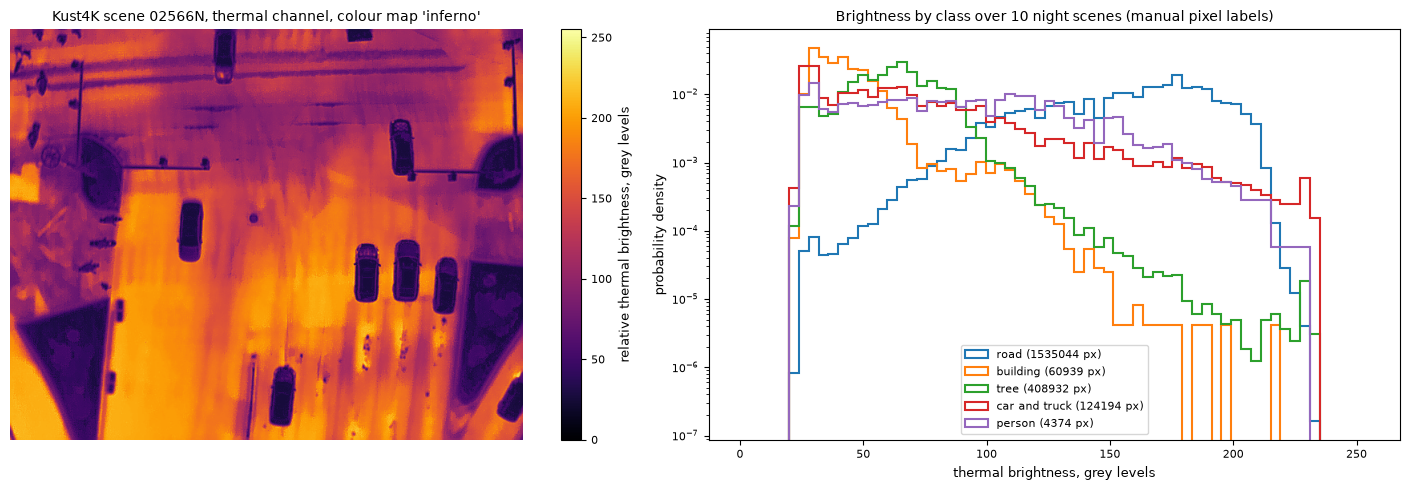

In [18]:
#@title 1.2.3-C Matplotlib: colour maps and histograms of real thermal images [auto] { run: "auto", display-mode: "form" }
COLORMAP = "inferno" #@param ["gray", "inferno", "jet", "turbo", "viridis", "hot"]
BINS = 64 #@param {type:"slider", min:16, max:128, step:8}
LIGHT = "night" #@param ["day", "night"]

ids = kust.DAY if LIGHT == "day" else kust.NIGHT
pairs = [kust.pair(i) for i in ids]
p0 = pairs[0]
fig, ax = plt.subplots(1, 2, figsize=(16, 5), gridspec_kw=dict(width_ratios=[1.1, 1]))
im = ax[0].imshow(p0["tir_gray"], cmap=COLORMAP, vmin=0, vmax=255)
plt.colorbar(im, ax=ax[0], fraction=0.04, label="relative thermal brightness, grey levels")
ax[0].set_title(f"Kust4K scene {p0['id']}, thermal channel, colour map '{COLORMAP}'")
ax[0].axis("off")
groups = {"road": [1], "building": [2], "tree": [6], "car and truck": [4, 5], "person": [7]}
for name, cls in groups.items():
    v = np.concatenate([p["tir_gray"][np.isin(p["labels"], cls)] for p in pairs])
    if v.size:
        ax[1].hist(v, bins=BINS, range=(0, 255), histtype="step", lw=1.5, density=True, label=f"{name} ({v.size} px)")
ax[1].set_xlabel("thermal brightness, grey levels")
ax[1].set_ylabel("probability density")
ax[1].set_yscale("log")
ax[1].legend(fontsize=8)
ax[1].set_title(f"Brightness by class over {len(pairs)} {LIGHT} scenes (manual pixel labels)")
plt.tight_layout()
plt.show()

### Block 1.2.3-D. PyTorch: from image to tensor; convolution as a layer of a neural network [auto]

**Purpose.** To convert a real frame into a tensor of the layout N × C × H × W, to run a convolution layer with a fixed kernel and to compare the result with the OpenCV filter. In a convolutional neural network (Topic 4) the same layer is used, but the values of the kernel are learned from data.

**Parameters.** `KERNEL_TYPE` — kernel of the convolution; `DEVICE` — device (`auto` = GPU when available).

**What to observe.** The shapes of the tensors at each step and the difference between PyTorch and OpenCV results (zero or about $10^{-6}$: both libraries compute the same cross-correlation, a difference is rounding of floating-point numbers).

gray: (512, 640) uint8 -> tensor x: (1, 1, 512, 640) torch.float32 on cpu
layer weights: (1, 1, 3, 3) (out_channels, in_channels, kH, kW) -> output y: (1, 1, 512, 640)
max |PyTorch - OpenCV| = 0.00e+00


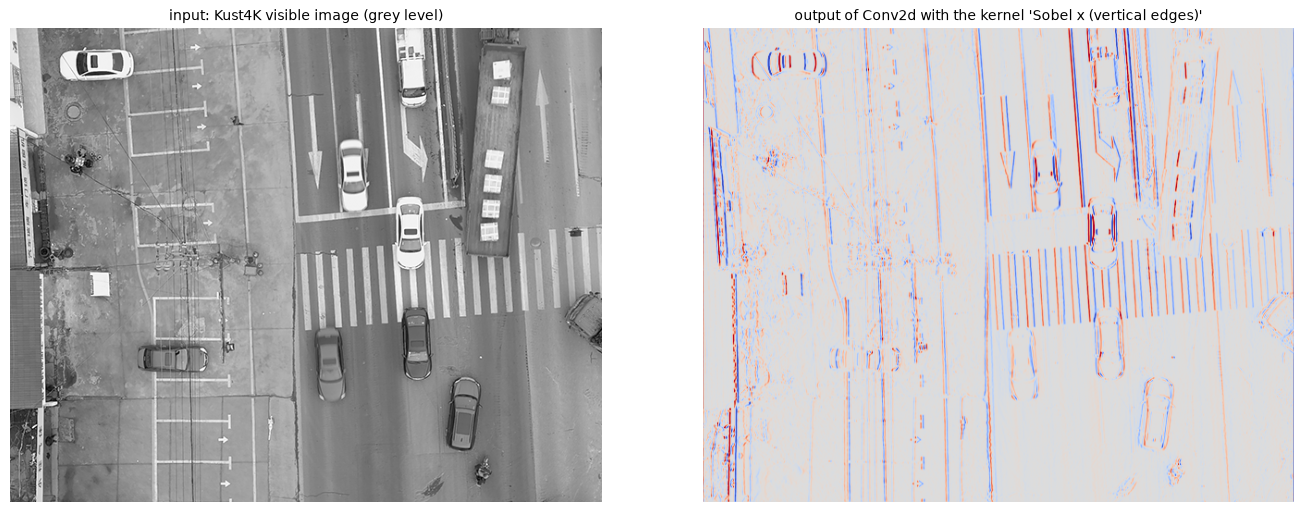

In [19]:
#@title 1.2.3-D PyTorch: image to tensor, convolution layer [auto] { run: "auto" }
KERNEL_TYPE = "Sobel x (vertical edges)" #@param ["Sobel x (vertical edges)", "Sobel y (horizontal edges)", "Laplacian", "sharpen", "box blur 5x5"]
DEVICE = "auto" #@param ["auto", "cpu", "cuda"]

if torch is None:
    print("PyTorch is not installed in this runtime.")
else:
    KERNELS = {"Sobel x (vertical edges)": [[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]],
               "Sobel y (horizontal edges)": [[-1, -2, -1], [0, 0, 0], [1, 2, 1]],
               "Laplacian": [[0, 1, 0], [1, -4, 1], [0, 1, 0]],
               "sharpen": [[0, -1, 0], [-1, 5, -1], [0, -1, 0]],
               "box blur 5x5": (np.ones((5, 5)) / 25).tolist()}
    kern = np.array(KERNELS[KERNEL_TYPE], np.float32)
    dev = ("cuda" if CUDA_OK else "cpu") if DEVICE == "auto" else DEVICE
    if dev == "cuda" and not CUDA_OK:
        print("CUDA is not available; the CPU is used.")
        dev = "cpu"
    rgb = kust.pair(kust.DAY[0])["rgb"]
    gray_ = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)                   # H x W, uint8
    x = torch.from_numpy(gray_).float().div(255.0)                   # H x W, float32 in [0, 1]
    x = x.unsqueeze(0).unsqueeze(0).to(dev)                          # N x C x H x W = 1 x 1 x H x W
    layer = torch.nn.Conv2d(1, 1, kernel_size=kern.shape[0], padding=kern.shape[0] // 2, bias=False).to(dev)
    with torch.no_grad():
        layer.weight.copy_(torch.from_numpy(kern)[None, None])
        y = layer(x)
    y_np = y[0, 0].cpu().numpy()
    ref = cv2.filter2D(gray_.astype(np.float32) / 255.0, -1, kern, borderType=cv2.BORDER_CONSTANT)
    print(f"gray: {gray_.shape} {gray_.dtype} -> tensor x: {tuple(x.shape)} {x.dtype} on {x.device}")
    print(f"layer weights: {tuple(layer.weight.shape)} (out_channels, in_channels, kH, kW) -> output y: {tuple(y.shape)}")
    print(f"max |PyTorch - OpenCV| = {np.abs(y_np - ref).max():.2e}")
    fig, ax = plt.subplots(1, 2, figsize=(14, 5.2))
    ax[0].imshow(gray_, cmap="gray")
    ax[0].set_title("input: Kust4K visible image (grey level)")
    smooth = KERNEL_TYPE in ("sharpen", "box blur 5x5")
    lim = np.percentile(np.abs(y_np), 99.5)
    ax[1].imshow(y_np, cmap="gray" if smooth else "coolwarm", vmin=None if smooth else -lim, vmax=None if smooth else lim)
    ax[1].set_title(f"output of Conv2d with the kernel '{KERNEL_TYPE}'")
    for a in ax:
        a.axis("off")
    plt.tight_layout()
    plt.show()

### Block 1.2.3-E. Ultralytics: a ready YOLO detector on real UAV data (optional, Internet is required)

**Purpose.** To see the interface of the library that is used in Topic 5 — loading of a pretrained model, detection on an image, the structure of the result — and to compare its detections with the manual annotation of real UAV frames.

**Parameters.** `RUN_YOLO` — install the library (about 1 min at the first run) and run the detector; `MODEL` — model size (n — nano, s — small); `CONF` — confidence threshold; `IMG_SIZE` — size of the input of the network (the frame is reduced to it); `IMAGE`, `FRAME_NUMBER` — real frame.

**Output.** The frame with the detections, the table of detections, and the share of annotated persons and cars found by the detector (a detection is correct when its box overlaps the annotated box with IoU ≥ 0.5; IoU is studied in Topic 5).

**What to observe.** The model is trained on the COCO data set of everyday photographs taken from the ground. On oblique VisDrone frames it finds the larger cars and some people, while small and distant objects are missed, especially at `IMG_SIZE` = 640, when a frame of 1360 px is reduced two times. On thermal frames and on vertical views it finds few or no objects: the view from above, the thermal "appearance" and the scale differ from its training data. This *domain gap* is overcome by additional training on data of the target domain (transfer learning, Topics 4–5).

**Note.** For a NumPy array the library expects the channel order BGR, as OpenCV does.

In [20]:
#@title 1.2.3-E Ultralytics YOLO detector on real UAV data (optional) { display-mode: "form" }
RUN_YOLO = False #@param {type:"boolean"}
MODEL = "yolo11n.pt" #@param ["yolo11n.pt", "yolo11s.pt"]
CONF = 0.25 #@param {type:"slider", min:0.05, max:0.9, step:0.05}
IMG_SIZE = "1280" #@param ["640", "960", "1280"]
IMAGE = "VisDrone visible" #@param ["VisDrone visible", "HIT-UAV thermal", "Kust4K visible, day", "Kust4K thermal, night", "GOOSE ground vehicle", "own frame (block 0.4)"]
FRAME_NUMBER = 1 #@param {type:"slider", min:1, max:8, step:1}

GROUPS = {"pedestrian": "person", "people": "person", "Person": "person", "person": "person",
          "car": "car", "van": "car", "Car": "car"}
if not RUN_YOLO:
    print("Tick RUN_YOLO and run the cell to install Ultralytics and run the detector.")
else:
    try:
        import ultralytics
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "ultralytics"], check=True)
        import ultralytics
    from ultralytics import YOLO
    print("Ultralytics", ultralytics.__version__)
    model = YOLO(MODEL)
    k_ = FRAME_NUMBER - 1
    gt = []
    if IMAGE.startswith("VisDrone"):
        rgb, gt = vis.load(vis.CURATED[k_])
    elif IMAGE.startswith("HIT"):
        img_, gt = hit.load(hit.EXAMPLES[k_])
        rgb = aitbc.to_rgb(img_)
    elif IMAGE.startswith("Kust4K"):
        p = kust.pair(kust.DAY[k_] if "day" in IMAGE else kust.NIGHT[k_])
        rgb = p["rgb"] if "visible" in IMAGE else p["tir"]
        gt = aitbc.boxes_from_labels(p["labels"], (4, 7), kust.CLASSES, min_area=30)
    elif IMAGE.startswith("GOOSE"):
        rgb, _ = goose.load(goose.CURATED[k_], scale=1.0)
    else:
        rgb = OWN_FRAME if OWN_FRAME is not None else vis.load(vis.CURATED[0])[0]
    res = model.predict(cv2.cvtColor(rgb, cv2.COLOR_RGB2BGR), conf=CONF, imgsz=int(IMG_SIZE), verbose=False)[0]
    b = res.boxes
    pred = [dict(cls=res.names[int(c)], box=v, conf=s) for c, v, s in zip(b.cls.tolist(), b.xyxy.tolist(), b.conf.tolist())]
    table = pd.DataFrame({"class": [p_["cls"] for p_ in pred], "confidence": [round(p_["conf"], 3) for p_ in pred],
                          "box [x1, y1, x2, y2]": [np.round(p_["box"], 1).tolist() for p_ in pred]})
    print(f"Detections: {len(table)} | inference time: {res.speed['inference']:.1f} ms | "
          f"image {rgb.shape[1]}x{rgb.shape[0]}, network input {IMG_SIZE}")
    display(table.head(10))
    if gt:
        rows = []
        for grp in ("person", "car"):
            g_boxes = [o["box"] for o in gt if GROUPS.get(o["cls"]) == grp]
            p_boxes = [p_["box"] for p_ in pred if p_["cls"] == grp]
            used, found = set(), 0
            for gb in g_boxes:
                best = max(((aitbc.box_iou(gb, pb), j) for j, pb in enumerate(p_boxes) if j not in used), default=(0, None))
                if best[0] >= 0.5:
                    used.add(best[1])
                    found += 1
            rows.append(dict(group=grp, annotated=len(g_boxes), detected=len(p_boxes), found_IoU_05=found,
                             recall=round(found / len(g_boxes), 2) if g_boxes else None))
        print("Comparison with the manual annotation:")
        display(pd.DataFrame(rows).set_index("group"))
    fig, ax = plt.subplots(figsize=(13, 7.5))
    ax.imshow(cv2.cvtColor(res.plot(), cv2.COLOR_BGR2RGB))
    ax.set_title(f"{MODEL}: detections with confidence >= {CONF} on {IMAGE}")
    ax.axis("off")
    plt.show()

Tick RUN_YOLO and run the cell to install Ultralytics and run the detector.


## 1.2.4. Typical project structure for UAV and UGV tasks

A computer vision project accumulates source data, intermediate frames, models and results. A fixed structure makes the work reproducible, allows a colleague to continue it and — in this course — collects the materials of the final mini-project (Lesson 5.4). All practical lessons use the structure

```
AITBC_project/
├── data/            source data: images, video, thermal frames, annotations
│   ├── images/
│   ├── video/
│   ├── thermal/
│   └── annotations/
├── frames/          frames extracted from video (by sensor)
│   ├── visible/
│   └── thermal/
├── models/          trained and exported models (.pt, .onnx)
├── outputs/         results: figures, processed video, tables, reports
│   ├── figures/
│   ├── video/
│   └── reports/
├── README.md        description of the project and the data
└── project.json     metadata: platform, sensors, versions of libraries, dates
```

Rules of work with the structure:
- source data in `data/` are not modified; every result is written to `outputs/`;
- file names contain the platform, the sensor, the date and the sequence number, e.g. `uav01_ir_20260415_0001.png`;
- every run records the versions of the libraries and the parameters (`project.json`, logs);
- annotations are stored separately from images, in an open format (JSON, YOLO text files).

### Block 1.2.4-A. Creation of the course project structure

**Purpose.** To create the standard structure in the course folder `STORAGE_ROOT` (block 1.2.2-B) and to save the first real data in it.

**Parameters.** `PROJECT_NAME` — name of the project folder; `PLATFORM`, `SENSORS` — metadata written to `project.json`; `SAVE_EXAMPLE_FRAMES` — save a thermal HIT-UAV frame with its boxes and a visible + thermal Kust4K pair with its pixel labels.

**Output.** The tree of the created folders and files. The file `data/SOURCES.md` records the origin and the licence of every saved frame. The same structure is checked and filled in the practical Lessons 1.3 and 1.4 (Notebook 02).

In [21]:
#@title 1.2.4-A Creating the course project structure { display-mode: "form" }
PROJECT_NAME = "AITBC_project" #@param {type:"string"}
PLATFORM = "reconnaissance UAV" #@param ["reconnaissance UAV", "FPV drone", "UGV"]
SENSORS = "visible + thermal" #@param ["visible", "thermal", "visible + thermal"]
SAVE_EXAMPLE_FRAMES = True #@param {type:"boolean"}

root = os.path.join(globals().get("STORAGE_ROOT", os.path.join(WORK_DIR, "AITBC")), PROJECT_NAME)
SUBDIRS = ["data/images", "data/video", "data/thermal", "data/annotations", "frames/visible",
           "frames/thermal", "models", "outputs/figures", "outputs/video", "outputs/reports"]
for d in SUBDIRS:
    os.makedirs(os.path.join(root, d), exist_ok=True)
meta = {"project": PROJECT_NAME, "course": "AI Technologies (Basic Course), AIT-BC",
        "platform": PLATFORM, "sensors": SENSORS, "created": time.strftime("%Y-%m-%d %H:%M:%S"),
        "python": platform.python_version(), "numpy": np.__version__, "opencv": cv2.__version__,
        "torch": TORCH_VERSION, "aitbc": aitbc.__version__, "data_cache": aitbc.DATA_ROOT}
with open(os.path.join(root, "project.json"), "w", encoding="utf-8") as fh:
    json.dump(meta, fh, indent=2, ensure_ascii=False)
if not os.path.exists(os.path.join(root, "README.md")):
    with open(os.path.join(root, "README.md"), "w", encoding="utf-8") as fh:
        fh.write(f"# {PROJECT_NAME}\n\nCourse project of AI Technologies (Basic Course).\n"
                 f"Platform: {PLATFORM}. Sensors: {SENSORS}.\n\n"
                 "data/ - source data (read only); frames/ - extracted frames; models/ - models; outputs/ - results.\n")
if SAVE_EXAMPLE_FRAMES:
    f = hit.EXAMPLES[0]
    img, objs = hit.load(f)
    name = "hituav_ir_" + f[:-4]
    cv2.imwrite(os.path.join(root, "data", "thermal", name + ".png"), img)
    r = hit.images.set_index("file").loc[f]
    ann = {"image": f"data/thermal/{name}.png", "source": "HIT-UAV, " + f, "width": int(img.shape[1]),
           "height": int(img.shape[0]), "altitude_m": int(r.altitude), "camera_angle_deg": int(r.angle),
           "night": bool(r.night), "gsd_m": round(hit.gsd(r.altitude, r.angle), 4),
           "objects": [{"class": o["cls"], "box_xyxy": [round(v, 1) for v in o["box"]]} for o in objs]}
    with open(os.path.join(root, "data", "annotations", name + ".json"), "w", encoding="utf-8") as fh:
        json.dump(ann, fh, indent=1)
    p = kust.pair(kust.NIGHT[0])
    cv2.imwrite(os.path.join(root, "data", "images", f"kust4k_eo_{p['id']}.png"), cv2.cvtColor(p["rgb"], cv2.COLOR_RGB2BGR))
    cv2.imwrite(os.path.join(root, "data", "thermal", f"kust4k_ir_{p['id']}.png"), cv2.cvtColor(p["tir"], cv2.COLOR_RGB2BGR))
    cv2.imwrite(os.path.join(root, "data", "annotations", f"kust4k_labels_{p['id']}.png"), p["labels"])
    with open(os.path.join(root, "data", "SOURCES.md"), "w", encoding="utf-8") as fh:
        fh.write("# Sources of the example data\n\n"
                 f"- thermal/{name}.png, annotations/{name}.json: HIT-UAV, file {f}. Suo J. et al., Scientific Data 10, 227 (2023), "
                 "https://doi.org/10.1038/s41597-023-02066-6. Licence CC BY 4.0.\n"
                 f"- images/kust4k_eo_{p['id']}.png, thermal/kust4k_ir_{p['id']}.png, annotations/kust4k_labels_{p['id']}.png: "
                 f"Kust4K, frame {p['id']}. Ouyang J. et al., Scientific Data 12, 1701 (2025), "
                 "https://doi.org/10.6084/m9.figshare.29476610. Licence CC BY 4.0. "
                 "Label values: " + ", ".join(f"{i} = {n}" for i, n in enumerate(kust.CLASSES)) + ".\n")


def print_tree(path, prefix=""):
    entries = sorted(os.listdir(path), key=lambda e: (not os.path.isdir(os.path.join(path, e)), e))
    for i, e in enumerate(entries):
        last = i == len(entries) - 1
        full = os.path.join(path, e)
        size = "" if os.path.isdir(full) else f"  ({os.path.getsize(full) / 1024:.0f} KB)"
        print(prefix + ("└── " if last else "├── ") + e + ("/" if os.path.isdir(full) else "") + size)
        if os.path.isdir(full):
            print_tree(full, prefix + ("    " if last else "│   "))


PROJECT_ROOT = root
print(PROJECT_ROOT + "/")
print_tree(PROJECT_ROOT)

/content/AITBC/AITBC_project/
├── data/
│   ├── annotations/
│   │   ├── hituav_ir_1_60_30_0_00047.json  (2 KB)
│   │   └── kust4k_labels_02566N.png  (9 KB)
│   ├── images/
│   │   └── kust4k_eo_02566N.png  (512 KB)
│   ├── thermal/
│   │   ├── hituav_ir_1_60_30_0_00047.png  (160 KB)
│   │   └── kust4k_ir_02566N.png  (621 KB)
│   ├── video/
│   └── SOURCES.md  (1 KB)
├── frames/
│   ├── thermal/
│   └── visible/
├── models/
├── outputs/
│   ├── figures/
│   ├── reports/
│   └── video/
├── README.md  (0 KB)
└── project.json  (0 KB)


### Summary of Lesson 1.2

- Google Colab provides a ready environment for prototyping: preinstalled libraries, GPU on request, forms for interactive parameters; the runtime is temporary, permanent storage is Google Drive.
- The GPU accelerates operations on large arrays; the acceleration factor (8) depends on the size of the task and on the time of data transfer; the choice of the algorithm (separable filter) can give a comparable gain.
- NumPy stores images, OpenCV processes them, Matplotlib displays them, PyTorch runs neural networks on CPU and GPU, Ultralytics gives ready detection models; the BGR/RGB order and the H × W × C / N × C × H × W layouts must be converted explicitly.
- All practical lessons use the project structure `data / frames / models / outputs` in the course folder.

### Control questions
1. What is lost when a Colab runtime is restarted, and what is kept? How are data kept between sessions?
2. How is the GPU enabled in Colab, and how can a program check that the GPU is available?
3. Why may an operation on a small image run faster on the CPU than on the GPU?
4. Which library is used for each step: reading a video, converting colours, showing a histogram, training a neural network, running a ready YOLO detector?
5. A frame read by OpenCV is shown with wrong colours. What is the reason and how is it corrected?
6. Convert the shape of a batch of 16 RGB frames 640 × 512 from the NumPy layout to the PyTorch layout. *(16 × 512 × 640 × 3 → 16 × 3 × 512 × 640.)*
7. Why are source data in `data/` never modified?

---
## Glossary

| Term | Meaning |
|---|---|
| AI, ML, deep learning | artificial intelligence; machine learning (parameters from data); learning with multi-layer neural networks |
| CV | computer vision: extraction of information from images and video |
| EO / LWIR | electro-optical (visible) channel / long-wave infrared (thermal) channel, 8–14 µm |
| Microbolometer | uncooled thermal sensor; its thermal time constant (about 10 ms) acts as an exposure time |
| AGC | automatic gain control: stretching of the brightness range in every thermal frame; brightness is then relative, not a temperature |
| White-hot / black-hot | grey-level display of a thermal image in which warm surfaces are bright / dark; colour palettes ("ironbow") map brightness to colours |
| Registration | geometric alignment of images of two sensors so that equal pixel coordinates show the same point of the scene |
| SCR | signal-to-clutter ratio (1): contrast of an object against the fluctuations of its background |
| FOV, HFOV | field of view; horizontal field of view |
| Nadir view, camera angle | vertical view down; angle of the optical axis below the horizon |
| GSD | ground sampling distance: size of the ground area covered by one pixel, m/px |
| Footprint | ground area covered by the image |
| Johnson criteria | pixels (cycles) across a target needed for detection, recognition, identification |
| Classification | one label for an image or a patch |
| Detection, bounding box | finding objects; rectangle $[x_1, y_1, x_2, y_2]$ around an object; an *oriented* box is rotated with the object |
| Confidence | score of a detection in the range 0…1 |
| Semantic / instance segmentation | class of every pixel (label map) / separate mask of every object |
| Tracking, track identifier | linking detections across frames; persistent number of an object |
| Phase correlation | estimation of the shift between two images from their Fourier transforms; used to compensate the camera motion |
| Recall, precision | share of found objects; share of correct detections |
| IoU | intersection over union of two boxes |
| PSNR, SSIM | measures of the difference between a clean and a degraded image |
| Motion blur, rolling shutter | smearing during the exposure; row-by-row distortion of a moving scene |
| Thermal crossover | equal thermal brightness of an object and its background (morning, evening) |
| Latency (delay) | time from the capture of a frame to the use of its result |
| Domain gap | difference between the training data of a model and the data of its application |
| Runtime | virtual machine that executes the notebook |
| GPU, CUDA | graphics processor; software platform of NVIDIA GPUs |
| Tensor | multi-dimensional array of PyTorch (layout N × C × H × W) |
| BGR / RGB | channel order of OpenCV / of Matplotlib and most neural networks |
| ONNX | open format for the exchange of trained neural networks |
| YOLO | family of one-stage real-time object detectors |

## Data sources and licences

The course library reads the files directly from the repositories of the authors; the data are not redistributed with the notebook. When images or results are published, the data sets are cited.

1. **HIT-UAV.** Suo J., Wang T., Zhang X., Chen H., Zhou W., Shi W. HIT-UAV: A high-altitude infrared thermal dataset for Unmanned Aerial Vehicle-based object detection. *Scientific Data*, 10, 227 (2023). https://doi.org/10.1038/s41597-023-02066-6 · Data: https://github.com/suojiashun/HIT-UAV-Infrared-Thermal-Dataset · Licence CC BY 4.0.
2. **Kust4K.** Ouyang J., Wang Q., Shang Y., Jin P., Zhong H., Zhou L., Shen T. An RGB-TIR dataset from UAV platform for robust urban traffic scenes semantic segmentation. *Scientific Data*, 12, 1701 (2025). https://doi.org/10.1038/s41597-025-05994-7 · Data: https://doi.org/10.6084/m9.figshare.29476610 · Licence CC BY 4.0. The data set contains frames with simulated sensor failures (visible image set to zero, thermal image blurred) made by its authors; the course uses only frames without them.
3. **VisDrone.** Zhu P., Wen L., Du D., Bian X., Fan H., Hu Q., Ling H. Detection and tracking meet drones challenge. *IEEE Transactions on Pattern Analysis and Machine Intelligence*, 44(11), 7380–7399 (2022). Data: https://github.com/VisDrone/VisDrone-Dataset (validation part of VisDrone2019-DET) · Terms of use: see the data set page.
4. **GOOSE.** Mortimer P., Hagmanns R., Granero M., Luettel T., Petereit J., Wuensche H.-J. The GOOSE dataset for perception in unstructured environments. *IEEE International Conference on Robotics and Automation (ICRA)*, 2024. https://arxiv.org/abs/2310.16788 · Data: https://goose-dataset.de (validation part of the 2D data) · Licence CC BY-SA 4.0.

**Next notebook.** Notebook 02 — Lessons 1.3 and 1.4 (practical): setting up Google Colab and first work with frames of electro-optical systems; processing of UAV and UGV video streams.